# TP Integrador — Análisis de Datos (CEIA · FIUBA · 4B 2026)
## Recorridos de Ecobici — Ciudad de Buenos Aires, año 2024

**Integrantes:** Juan Palomeque · Juan Pablo Alegre · Tomás Moretti

**Problema de ML supervisado:** predecir la **duración de un viaje en Ecobici** (en minutos) en el momento en que el usuario retira la bicicleta e indica a qué estación va.
- Tipo de problema: **regresión** (target = `duracion_min`, una cantidad continua).

### Índice
1. Carga y descripción general
2. Limpieza básica (tipos, duplicados, consistencia)
3. EDA univariado (numéricas, categóricas, temporales)
4. EDA bivariado / multivariado + tests y medidas de asociación
5. Valores faltantes y su tipo (MCAR / MAR / MNAR / estructural)
6. Outliers y errores
7. Planteo del problema de ML
8. Limpieza general del dataset
9. Split train / test
10. Tratamiento de faltantes
11. Tratamiento de outliers
12. Feature engineering (creación de features)
13. Discretización
14. Codificación
15. Escalado
16. Desbalance de clases: no aplica (problema de regresión)
17. Selección de features
18. Extracción de features: PCA
19. Conclusiones

> Flujo de preparación que seguimos (clases 4 a 7): **split → tratar nulos → tratar outliers → crear features → discretizar → codificar → escalar → (balancear: solo en clasificación) → reducir dimensionalidad**. Todo lo que requiere *calcular* algo (medias, percentiles, categorías, escalas) se calcula **solo en TRAIN** y se **aplica** a TEST, para no filtrar información del test (data leakage).

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno                      # visualización de faltantes (clase 3)
from scipy import stats as st
from scipy.stats import chi2_contingency, f_oneway, pointbiserialr, entropy

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, KBinsDiscretizer
from category_encoders import TargetEncoder   # pip install category_encoders (clase 4)
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.decomposition import PCA

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 90
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

SEED = 42          # semilla para que los resultados sean reproducibles
MUESTRA = 200_000  # tamaño de muestra para gráficos / cálculos pesados (el dataset tiene 3,5 millones de filas)

# 1. Carga y descripción general del dataset
Fuente: *Buenos Aires Data — Bicicletas públicas, recorridos realizados 2024*. Cada fila es **un viaje** (recorrido).

In [2]:
RUTA = 'badata_ecobici_recorridos_realizados_2024.csv'
df = pd.read_csv(RUTA)

print(f'Observaciones (filas): {df.shape[0]:,}')
print(f'Variables (columnas):  {df.shape[1]}')
print(f'Memoria: {df.memory_usage(deep=True).sum()/1e9:.2f} GB')
df.head()

Observaciones (filas): 3,559,284
Variables (columnas):  17
Memoria: 0.95 GB


,id_recorrido,duracion_recorrido,fecha_origen_recorrido,id_estacion_origen,nombre_estacion_origen,direccion_estacion_origen,long_estacion_origen,lat_estacion_origen,fecha_destino_recorrido,id_estacion_destino,nombre_estacion_destino,direccion_estacion_destino,long_estacion_destino,lat_estacion_destino,id_usuario,modelo_bicicleta,genero
0,20428222,568,2024-01-23 18:36:00,513,308 - SAN MARTIN II,Av. San Martín 5129,-58.491,-34.597,2024-01-23 18:45:28,498,055 - HABANA,Gral. José Gervasio Artigas 4298 (y Habana),-58.495,-34.587,"992,557.000",FIT,MALE
1,20431744,1355,2024-01-23 22:41:20,460,133 - BEIRO Y SEGUROLA,Segurola 3194,-58.512,-34.608,2024-01-23 23:03:55,382,204 - Biarritz,Biarritz 2403,-58.477,-34.605,"320,782.000",FIT,FEMALE
2,20429936,0,2024-01-23 20:06:22,467,328 - SARMIENTO II,Sarmiento 2037,-58.396,-34.606,2024-01-23 20:06:22,6,006 - Parque Lezama,"Avenida Martin Garcia, 295",-58.370,-34.629,"828,678.000",FIT,FEMALE
3,20429976,0,2024-01-23 20:08:17,382,204 - Biarritz,Biarritz 2403,-58.477,-34.605,2024-01-23 20:08:17,460,133 - BEIRO Y SEGUROLA,Segurola 3194,-58.512,-34.608,"320,782.000",ICONIC,FEMALE
4,20424802,680,2024-01-23 15:18:39,137,137 - AZOPARDO Y CHILE,AZOPARDO 700,-58.367,-34.616,2024-01-23 15:29:59,150,150 - RODRIGO BUENO,Av. España 2200,-58.355,-34.619,"861,425.000",FIT,FEMALE


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3559284 entries, 0 to 3559283
Data columns (total 17 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   id_recorrido                int64  
 1   duracion_recorrido          int64  
 2   fecha_origen_recorrido      str    
 3   id_estacion_origen          int64  
 4   nombre_estacion_origen      str    
 5   direccion_estacion_origen   str    
 6   long_estacion_origen        float64
 7   lat_estacion_origen         float64
 8   fecha_destino_recorrido     str    
 9   id_estacion_destino         int64  
 10  nombre_estacion_destino     str    
 11  direccion_estacion_destino  str    
 12  long_estacion_destino       float64
 13  lat_estacion_destino        float64
 14  id_usuario                  float64
 15  modelo_bicicleta            str    
 16  genero                      str    
dtypes: float64(5), int64(4), str(8)
memory usage: 910.5 MB


### Tipo de cada variable (clase 1: numéricas discretas/continuas, categóricas nominales/ordinales)
Ojo: que pandas guarde algo como número **no** significa que sea una variable numérica. Los `id` son números que funcionan como **etiquetas** (categóricas nominales).

In [4]:
tipos = pd.DataFrame({
    'dtype_pandas': df.dtypes.astype(str),
    'valores_unicos': df.nunique(),
    'tipo_estadistico': [
        'Identificador (nominal, cardinalidad extrema)',  # id_recorrido
        'Numérica continua (segundos) -> TARGET',          # duracion_recorrido
        'Fecha/hora (numérica o categórica según uso)',    # fecha_origen
        'Categórica nominal (alta cardinalidad)',          # id_estacion_origen
        'Categórica nominal (redundante con id)',          # nombre_estacion_origen
        'Categórica nominal (redundante con id)',          # direccion_estacion_origen
        'Numérica continua (coordenada)',                  # long origen
        'Numérica continua (coordenada)',                  # lat origen
        'Fecha/hora',                                      # fecha_destino
        'Categórica nominal (alta cardinalidad)',          # id_estacion_destino
        'Categórica nominal (redundante con id)',
        'Categórica nominal (redundante con id)',
        'Numérica continua (coordenada)',
        'Numérica continua (coordenada)',
        'Identificador de usuario (nominal, cardinalidad muy alta)',
        'Categórica binaria',                              # modelo_bicicleta
        'Categórica nominal',                              # genero
    ]})
tipos

,dtype_pandas,valores_unicos,tipo_estadistico
id_recorrido,int64,3559283,"Identificador (nominal, cardinalidad extrema)"
duracion_recorrido,int64,19543,Numérica continua (segundos) -> TARGET
fecha_origen_recorrido,str,3227772,Fecha/hora (numérica o categórica según uso)
id_estacion_origen,int64,395,Categórica nominal (alta cardinalidad)
nombre_estacion_origen,str,395,Categórica nominal (redundante con id)
direccion_estacion_origen,str,393,Categórica nominal (redundante con id)
long_estacion_origen,float64,395,Numérica continua (coordenada)
lat_estacion_origen,float64,395,Numérica continua (coordenada)
fecha_destino_recorrido,str,3220154,Fecha/hora
id_estacion_destino,int64,398,Categórica nominal (alta cardinalidad)


**Lectura:** el dataset tiene 3,56 millones de viajes y 17 variables. Hay pocas variables realmente "medidas" (duración, coordenadas); la mayoría son **categóricas** (estaciones, usuario, género, modelo) y **fechas**. Las estaciones tienen **alta cardinalidad** (~400 valores) y el usuario **cardinalidad muy alta** (~263 mil). Esto condiciona la codificación más adelante.

# 2. Limpieza básica (data cleaning — clase 4)
Antes de explorar a fondo corregimos lo que es claramente un problema de **calidad**: tipos de datos incorrectos, duplicados y consistencia interna.

In [5]:
# 2.1 Identificamos y ajustamos los tipos de variables
# Pandas no necesariamente asigna el dtype en forma correcta al importar.
# Conviene revisar cada variable y asignar el tipo de dato correcto.

ecobici_numericas = ['duracion_recorrido', 'long_estacion_origen', 'lat_estacion_origen',
                     'long_estacion_destino', 'lat_estacion_destino']
ecobici_cat_nom   = ['nombre_estacion_origen', 'direccion_estacion_origen',
                     'nombre_estacion_destino', 'direccion_estacion_destino',
                     'modelo_bicicleta', 'genero']

dtype_map = {col: 'float64'  for col in ecobici_numericas}       # Creamos un mapping para las numéricas
dtype_map.update({col: 'category' for col in ecobici_cat_nom})   # Adicionamos el mapping para las nominales
df = df.astype(dtype_map)                                        # Aplicamos el mapping al DataFrame

# Las fechas vienen como texto -> datetime
df['fecha_origen_recorrido']  = pd.to_datetime(df['fecha_origen_recorrido'])
df['fecha_destino_recorrido'] = pd.to_datetime(df['fecha_destino_recorrido'])

# Los id son categóricas nominales, pero los dejamos como enteros porque los usamos como "claves"
# (agrupar, contar, codificar). id_usuario viene como float -> entero
df['id_usuario'] = df['id_usuario'].astype('int64')
print(df.dtypes)

# 2.2 Duplicados
print('Filas duplicadas exactas:', df.duplicated().sum())
print('id_recorrido repetidos:  ', df['id_recorrido'].duplicated().sum())
df = df.drop_duplicates(subset='id_recorrido', keep='first').reset_index(drop=True)
print('Filas luego de quitar duplicados:', f'{len(df):,}')

id_recorrido                           int64
duracion_recorrido                   float64
fecha_origen_recorrido        datetime64[us]
id_estacion_origen                     int64
nombre_estacion_origen              category
direccion_estacion_origen           category
long_estacion_origen                 float64
lat_estacion_origen                  float64
fecha_destino_recorrido       datetime64[us]
id_estacion_destino                    int64
nombre_estacion_destino             category
direccion_estacion_destino          category
long_estacion_destino                float64
lat_estacion_destino                 float64
id_usuario                             int64
modelo_bicicleta                    category
genero                              category
dtype: object
Filas duplicadas exactas: 1
id_recorrido repetidos:   1
Filas luego de quitar duplicados: 3,559,283


In [6]:
# 2.3 Consistencia interna
# a) ¿La duración informada coincide con (fecha_destino - fecha_origen)?
dur_calc = (df['fecha_destino_recorrido'] - df['fecha_origen_recorrido']).dt.total_seconds()
coincide = (dur_calc == df['duracion_recorrido'])
print(f"Duración coincide con la diferencia de fechas: {coincide[dur_calc.notna()].mean():.2%} de los viajes con fecha destino")

# b) ¿Cada id de estación tiene un único nombre / coordenada?
for lado in ['origen', 'destino']:
    n = df.groupby(f'id_estacion_{lado}')[[f'nombre_estacion_{lado}', f'lat_estacion_{lado}']].nunique().max()
    print(f'Máx. nombres / latitudes distintos por id_estacion_{lado}:', n.values)

# c) Período cubierto
print('Desde', df['fecha_origen_recorrido'].min(), 'hasta', df['fecha_origen_recorrido'].max())

# d) ¿Cada usuario tiene un único género?
print('Géneros distintos por usuario:', df.groupby('id_usuario')['genero'].nunique().value_counts().to_dict())

Duración coincide con la diferencia de fechas: 100.00% de los viajes con fecha destino
Máx. nombres / latitudes distintos por id_estacion_origen: [1 1]
Máx. nombres / latitudes distintos por id_estacion_destino: [1 1]
Desde 2024-01-01 00:06:50 hasta 2024-12-31 23:58:25
Géneros distintos por usuario: {1: 262138, 0: 535}


**Conclusiones de la limpieza básica**
- Había **1 registro duplicado** (mismo `id_recorrido`) → se eliminó.
- La duración es consistente con las fechas en el 99,9% de los casos: `duracion_recorrido` **es literalmente** `fecha_destino − fecha_origen`. Esto es importante: la fecha de destino **revela la target** (leakage) y no podrá usarse como feature.
- Cada `id_estacion` tiene un único nombre, dirección y coordenada → `nombre_*` y `direccion_*` son **redundantes** con el id.
- El género es un **atributo del usuario** (cada usuario tiene siempre el mismo valor). Esto nos va a servir para entender sus faltantes.

# 3. EDA univariado (clase 2)
## 3.1 Variable numérica principal: duración del viaje
Usamos **estadística clásica** (media, desvío, asimetría, curtosis) y **estadística robusta** (mediana, IQR, MAD), que no se deja arrastrar por los valores extremos.

In [7]:
df['duracion_min'] = df['duracion_recorrido'] / 60
d = df['duracion_min']

resumen = pd.Series({
    'media': d.mean(), 'desvío estándar': d.std(),
    'mediana (Q2)': d.median(), 'Q1': d.quantile(.25), 'Q3': d.quantile(.75),
    'IQR': d.quantile(.75) - d.quantile(.25),
    'MAD': st.median_abs_deviation(d.sample(MUESTRA, random_state=SEED)),
    'media recortada 5%': st.trim_mean(d, 0.05),
    'mínimo': d.min(), 'máximo': d.max(),
    'asimetría': d.skew(), 'curtosis (exceso)': d.kurtosis()})
resumen.to_frame('duración (min)')

,duración (min)
media,21.247
desvío estándar,159.737
mediana (Q2),14.683
Q1,8.217
Q3,24.567
IQR,16.350
MAD,7.633
media recortada 5%,16.895
mínimo,0.000
máximo,"42,852.750"


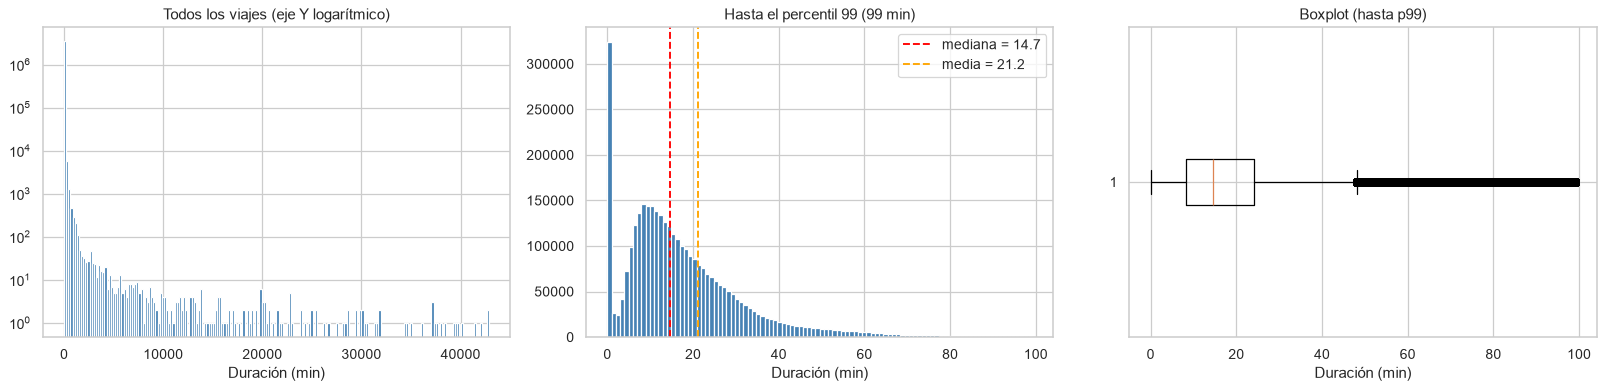

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(d, bins=200, color='steelblue')
axes[0].set_yscale('log')
axes[0].set_title('Todos los viajes (eje Y logarítmico)')
axes[0].set_xlabel('Duración (min)')

p99 = d.quantile(.99)
axes[1].hist(d[d <= p99], bins=100, color='steelblue')
axes[1].axvline(d.median(), color='red', ls='--', label=f'mediana = {d.median():.1f}')
axes[1].axvline(d.mean(), color='orange', ls='--', label=f'media = {d.mean():.1f}')
axes[1].set_title(f'Hasta el percentil 99 ({p99:.0f} min)')
axes[1].set_xlabel('Duración (min)'); axes[1].legend()

axes[2].boxplot(d[d <= p99], orientation='horizontal')
axes[2].set_title('Boxplot (hasta p99)'); axes[2].set_xlabel('Duración (min)')
plt.tight_layout(); plt.show()

**Interpretación:**
- La duración tiene **asimetría positiva extrema** (≈156) y **curtosis enorme** (distribución *leptocúrtica*, colas muy pesadas). La media (21 min) queda por encima de la mediana (≈15 min) y el desvío (≈160 min) es mucho mayor que la media: **la media y el desvío no representan bien los datos** → preferimos mediana e IQR.
- La mayoría de los viajes dura entre **8 y 25 min** (Q1–Q3).
- Se ve una **acumulación en 0–2 min** (sospechosa, la analizamos en la sección 6) y una **cola larga** con viajes de días (máx. ≈ 30 días).

## 3.2 Variables categóricas: frecuencias, moda y entropía de Shannon

In [9]:
def print_categorias(dataframe, columna):
    print(f"Cantidad de categorías que tiene la variable '{columna}': {dataframe[columna].nunique()}\n")
    print(f"Nombres de categorías presentes en la variable '{columna}': {dataframe[columna].unique()}\n")

    freq = dataframe[columna].value_counts()
    freq_rel = dataframe[columna].value_counts(normalize=True).mul(100).round(2)

    freq_tabla = pd.DataFrame({'Frecuencia absoluta': freq, 'Frecuencia relativa (%)': freq_rel})

    print(f"Frecuencias de cada categoría en la variable '{columna}':\n{freq_tabla}\n")

print_categorias(df, 'genero')
print_categorias(df, 'modelo_bicicleta')

# count = cant. de datos no nulos | unique = cantidad de categorías | top = moda | freq = frecuencia de la moda
df[ecobici_cat_nom].describe(include='category')

Cantidad de categorías que tiene la variable 'genero': 3

Nombres de categorías presentes en la variable 'genero': ['MALE', 'FEMALE', 'OTHER', NaN]
Categories (3, str): ['FEMALE', 'MALE', 'OTHER']

Frecuencias de cada categoría en la variable 'genero':
        Frecuencia absoluta  Frecuencia relativa (%)
genero                                              
MALE                2147720                   60.540
FEMALE              1133660                   31.960
OTHER                265957                    7.500

Cantidad de categorías que tiene la variable 'modelo_bicicleta': 2

Nombres de categorías presentes en la variable 'modelo_bicicleta': ['FIT', 'ICONIC']
Categories (2, str): ['FIT', 'ICONIC']

Frecuencias de cada categoría en la variable 'modelo_bicicleta':
                  Frecuencia absoluta  Frecuencia relativa (%)
modelo_bicicleta                                              
FIT                           2582442                   72.560
ICONIC                         976

,nombre_estacion_origen,direccion_estacion_origen,nombre_estacion_destino,direccion_estacion_destino,modelo_bicicleta,genero
count,3559283,3559283,3559283,3559283,3559283,3547337
unique,395,393,398,395,2,3
top,147 - Constitución,Avenida Juan de Garay 1050,147 - Constitución,Avenida Juan de Garay 1050,FIT,MALE
freq,38237,38237,38281,38281,2582442,2147720


In [10]:
# Entropía de Shannon (clase 2): mide qué tan repartidas están las categorías
for col in ['genero', 'modelo_bicicleta', 'id_estacion_origen', 'id_estacion_destino', 'id_usuario']:
    counts = df[col].value_counts()          # Cuento ocurrencias de cada categoría
    pi = counts / counts.sum()               # Calculo las pi (frecuencias relativas)
    H_max = np.log2(df[col].nunique())       # Entropía máxima (todas las categorías igual de probables)
    H_Shannon = entropy(pi, base=2)          # Entropía de Shannon con Scipy
    print(f"{col:22s} Entropía H: {H_Shannon:.2f} - Entropía máxima H_max: {H_max:.2f} - H/H_max: {H_Shannon/H_max:.2f}")

genero                 Entropía H: 1.24 - Entropía máxima H_max: 1.58 - H/H_max: 0.79
modelo_bicicleta       Entropía H: 0.85 - Entropía máxima H_max: 1.00 - H/H_max: 0.85
id_estacion_origen     Entropía H: 8.28 - Entropía máxima H_max: 8.63 - H/H_max: 0.96
id_estacion_destino    Entropía H: 8.28 - Entropía máxima H_max: 8.64 - H/H_max: 0.96
id_usuario             Entropía H: 16.30 - Entropía máxima H_max: 18.00 - H/H_max: 0.91


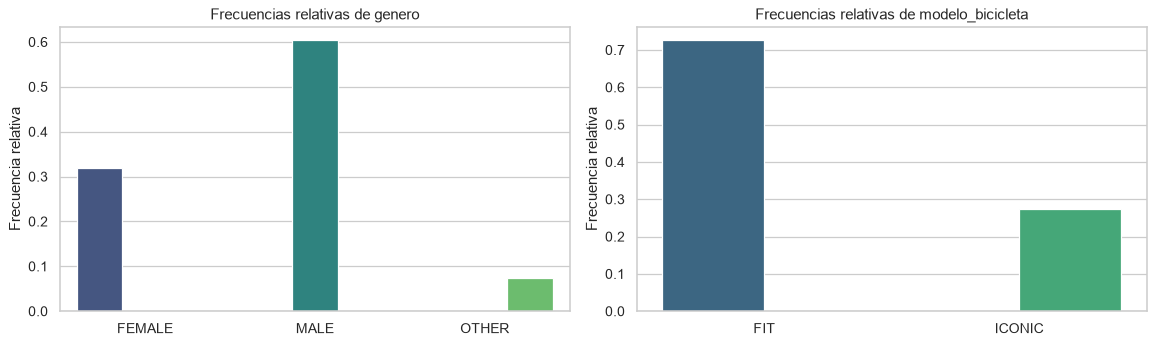

Viajes sin dato de género: 0.34%


In [11]:
# Frecuencias relativas de las categóricas (clase 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ['genero', 'modelo_bicicleta']):
    relative_freq = df[col].value_counts() / len(df)
    sns.barplot(x=relative_freq.index, y=relative_freq.values, hue=relative_freq.index,
                palette='viridis', ax=ax, legend=False)
    ax.set_title(f'Frecuencias relativas de {col}')
    ax.set_ylabel('Frecuencia relativa'); ax.set_xlabel('')
plt.tight_layout(); plt.show()
print(f"Viajes sin dato de género: {df['genero'].isna().mean():.2%}")

**Interpretación:** 60% de los viajes son de usuarios `MALE`, 32% `FEMALE`, 7,5% `OTHER` y 0,34% sin dato. El modelo de bici `FIT` (mecánica) concentra el 73% de los viajes y `ICONIC` el 27%. Las estaciones tienen entropía normalizada alta (el uso está bastante repartido entre muchas estaciones), y los usuarios también: hay muchísimos usuarios con pocos viajes.

## 3.3 Variables temporales (fecha de origen)

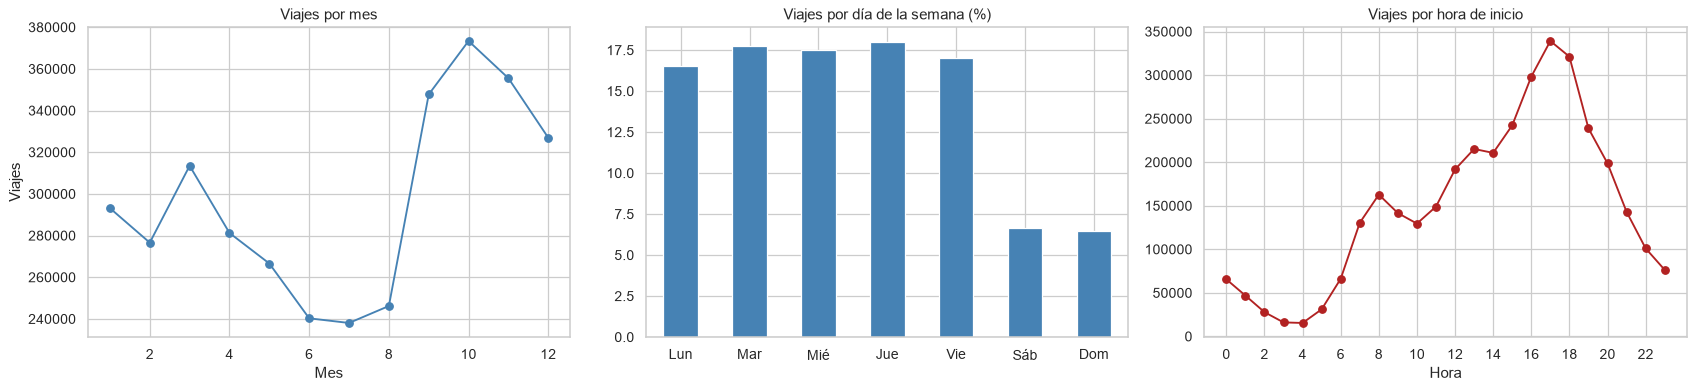

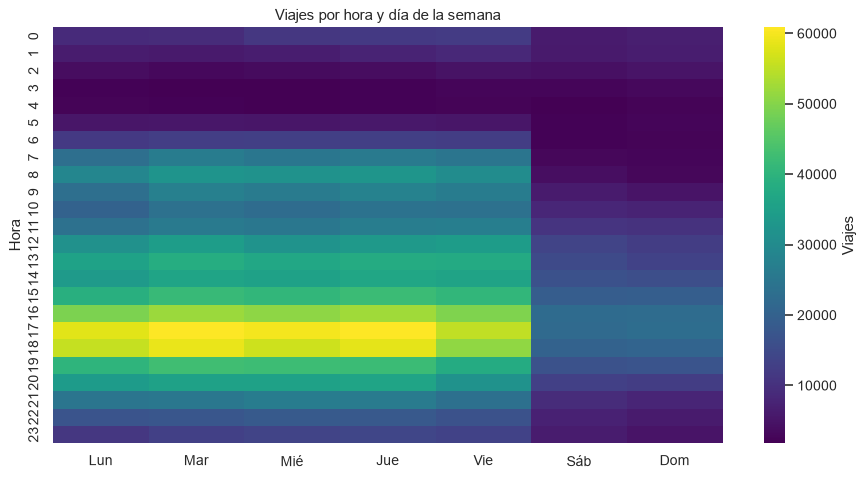

In [12]:
fo = df['fecha_origen_recorrido']
dias = {0: 'Lun', 1: 'Mar', 2: 'Mié', 3: 'Jue', 4: 'Vie', 5: 'Sáb', 6: 'Dom'}

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
fo.dt.month.value_counts().sort_index().plot(ax=axes[0], marker='o', color='steelblue')
axes[0].set_title('Viajes por mes'); axes[0].set_xlabel('Mes'); axes[0].set_ylabel('Viajes')

(fo.dt.dayofweek.value_counts(normalize=True).sort_index().rename(index=dias) * 100).plot.bar(ax=axes[1], color='steelblue')
axes[1].set_title('Viajes por día de la semana (%)'); axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=0)

fo.dt.hour.value_counts().sort_index().plot(ax=axes[2], marker='o', color='firebrick')
axes[2].set_title('Viajes por hora de inicio'); axes[2].set_xlabel('Hora'); axes[2].set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

tabla = pd.crosstab(fo.dt.hour, fo.dt.dayofweek).rename(columns=dias)
plt.figure(figsize=(12, 6))
sns.heatmap(tabla, cmap='viridis', cbar_kws={'label': 'Viajes'})
plt.title('Viajes por hora y día de la semana'); plt.ylabel('Hora'); plt.xlabel('')
plt.show()

**Interpretación:**
- **Patrón laboral muy marcado**: los días hábiles concentran ~87% de los viajes; sábado y domingo apenas ~6,5% cada uno.
- En días hábiles hay **dos picos**: ~8 h (ida al trabajo) y ~17–18 h (vuelta), el de la tarde más fuerte. Los fines de semana el uso es bajo y se reparte en la tarde. → La Ecobici se usa principalmente como **medio de transporte al trabajo/estudio**, no como paseo.
- Por mes: menos uso en invierno (jun–ago) y un salto desde septiembre (primavera).
- Esto sugiere features: **hora**, **día de semana / fin de semana**, **hora pico**, **mes** (estacionalidad).

## 3.4 Variables espaciales: ubicación de las estaciones

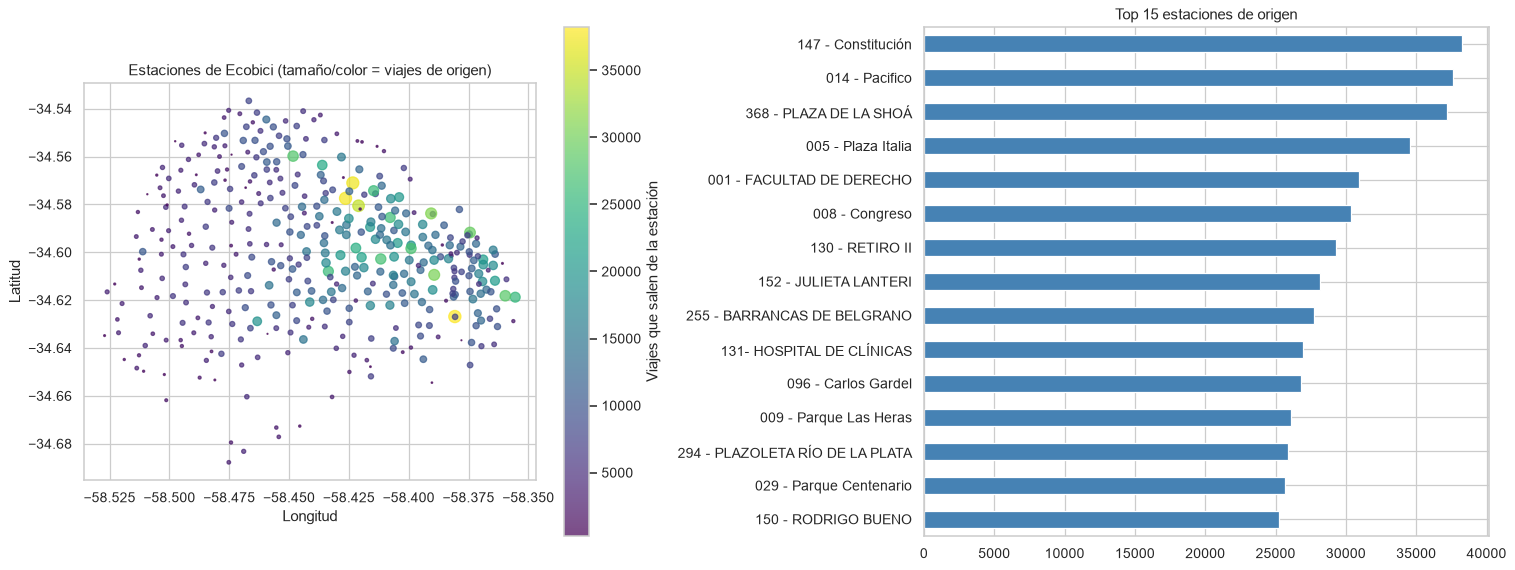

In [13]:
est = (df.groupby('id_estacion_origen')
         .agg(lat=('lat_estacion_origen', 'first'), lon=('long_estacion_origen', 'first'),
              viajes=('id_recorrido', 'size'), nombre=('nombre_estacion_origen', 'first')))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sc = axes[0].scatter(est['lon'], est['lat'], s=est['viajes'] / 400, c=est['viajes'], cmap='viridis', alpha=.7)
plt.colorbar(sc, ax=axes[0], label='Viajes que salen de la estación')
axes[0].set_title('Estaciones de Ecobici (tamaño/color = viajes de origen)')
axes[0].set_xlabel('Longitud'); axes[0].set_ylabel('Latitud'); axes[0].set_aspect('equal')

est.nlargest(15, 'viajes').set_index('nombre')['viajes'].sort_values().plot.barh(ax=axes[1], color='steelblue')
axes[1].set_title('Top 15 estaciones de origen'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()

**Interpretación:** el mapa reproduce la forma de CABA. Las estaciones con más viajes se concentran en el **centro y corredores hacia el norte** (Retiro, Constitución, Pacífico, Facultad de Derecho…), zonas de trabajo y nodos de transporte. El sur y oeste tienen menos estaciones y menos uso. Las coordenadas permiten **calcular la distancia entre estaciones**, que esperamos sea la feature más importante para predecir la duración.

# 4. EDA bivariado / multivariado
Para no saturar los gráficos usamos una **muestra aleatoria** de 200 mil viajes y recortamos al p99 para *visualizar* (no para limpiar).

In [14]:
# distancia en línea recta entre estaciones (fórmula de haversine)
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df['distancia_km'] = haversine_km(df['lat_estacion_origen'], df['long_estacion_origen'],
                                  df['lat_estacion_destino'], df['long_estacion_destino'])
df['mismo_origen_destino'] = (df['id_estacion_origen'] == df['id_estacion_destino']).astype(int)

m = df.sample(MUESTRA, random_state=SEED)
m = m[(m['duracion_min'] > 0) & (m['duracion_min'] <= m['duracion_min'].quantile(.99))]
m['dia'] = m['fecha_origen_recorrido'].dt.dayofweek.map(dias)

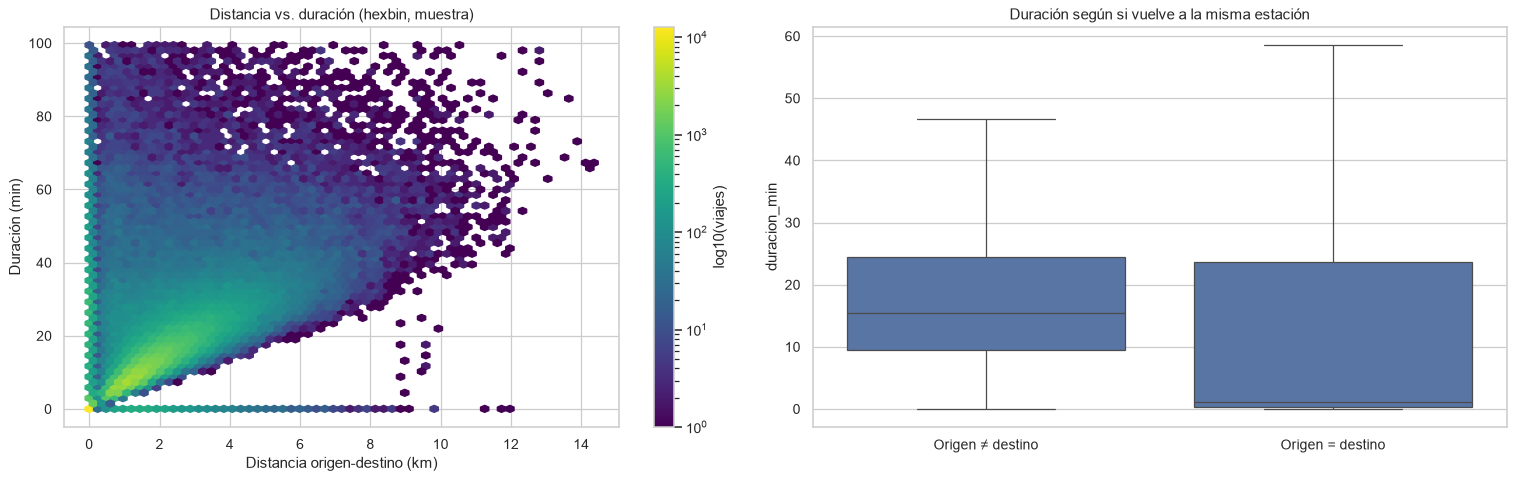

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
hb = axes[0].hexbin(m['distancia_km'], m['duracion_min'], gridsize=60, bins='log', cmap='viridis')
plt.colorbar(hb, ax=axes[0], label='log10(viajes)')
axes[0].set_xlabel('Distancia origen-destino (km)'); axes[0].set_ylabel('Duración (min)')
axes[0].set_title('Distancia vs. duración (hexbin, muestra)')

sns.boxplot(data=m, x='mismo_origen_destino', y='duracion_min', ax=axes[1], showfliers=False)
axes[1].set_xticklabels(['Origen ≠ destino', 'Origen = destino'])
axes[1].set_xlabel(''); axes[1].set_title('Duración según si vuelve a la misma estación')
plt.tight_layout(); plt.show()

**Interpretación:**
- Entre distancia y duración hay una **relación positiva** (más lejos → más tiempo), pero con mucha dispersión: para una misma distancia hay viajes rápidos y viajes muy largos (paradas intermedias, paseos). La relación **no es perfectamente lineal**.
- Abajo se ve una fila de viajes de distancia > 0 y duración casi 0: velocidades imposibles (errores, sección 6).
- Hay una franja de viajes con **distancia = 0** (vuelven a la misma estación) que se comportan distinto: o duran casi 0 min (devoluciones inmediatas) o son paseos largos. Por eso `mismo_origen_destino` es un feature útil.

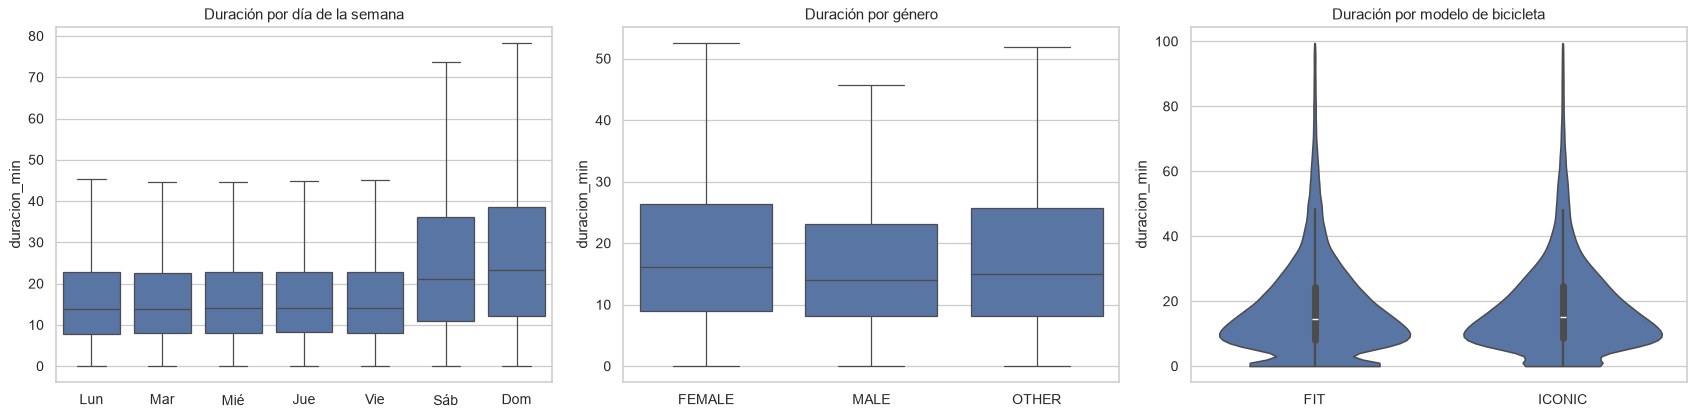

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
sns.boxplot(data=m, x='dia', y='duracion_min', order=list(dias.values()), ax=axes[0], showfliers=False)
axes[0].set_title('Duración por día de la semana'); axes[0].set_xlabel('')
sns.boxplot(data=m, x='genero', y='duracion_min', ax=axes[1], showfliers=False)
axes[1].set_title('Duración por género'); axes[1].set_xlabel('')
sns.violinplot(data=m, x='modelo_bicicleta', y='duracion_min', ax=axes[2], cut=0)
axes[2].set_title('Duración por modelo de bicicleta'); axes[2].set_xlabel('')
plt.tight_layout(); plt.show()

**Interpretación:** los viajes de **fin de semana son más largos** (mediana mayor y más dispersión: uso recreativo). Entre géneros hay diferencias pequeñas (`FEMALE` algo más largos). La bici `ICONIC` muestra viajes algo más largos que la `FIT`. Para saber si estas diferencias son **reales o producto del azar** usamos tests de hipótesis (clase 3).

## 4.1 Tests estadísticos y medidas de asociación (clase 3)
- **ANOVA** (numérica vs. categórica): ¿la duración media difiere según género / día? + **Eta cuadrado** (tamaño del efecto).
- **Chi-cuadrado de independencia** (categórica vs. categórica): ¿género y modelo de bici están relacionados? + **V de Cramér**.
- **Spearman** (numérica vs. numérica, relación monótona, robusta a outliers).

Con millones de filas casi cualquier diferencia da "significativa" (p-valor ≈ 0), por eso miramos también el **tamaño del efecto** (eta², V de Cramér).

In [17]:
# Funciones de la clase 3 (medidas de asociación)

def eta_squared(continuous, categorical):
    mask       = continuous.notna() & categorical.notna()
    y, grp     = continuous[mask], categorical[mask]
    groups     = [g.values for _, g in y.groupby(grp, observed=True)]
    F, p       = f_oneway(*groups)
    grand_mean = y.mean()
    ss_total   = ((y - grand_mean) ** 2).sum()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    return ss_between / ss_total, p, F

# Funcioncita para calcular Cramér's V entre dos variables categóricas x e y
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * min(k - 1, r - 1)))

In [18]:
# ANOVA + Eta cuadrado (numérica - categórica)
for col in ['genero', 'dia', 'modelo_bicicleta']:
    eta2, p, F = eta_squared(m['duracion_min'], m[col])
    print(f'ANOVA duración ~ {col:17s}: F = {F:9.1f}  p-valor = {p:.2e}  eta² = {eta2:.4f}')

# Chi-cuadrado de independencia + V de Cramér (categórica - categórica)
mask = df['genero'].notna()
tabla = pd.crosstab(df.loc[mask, 'genero'], df.loc[mask, 'modelo_bicicleta'])
chi2_, p, dof, esperadas = chi2_contingency(tabla)
print(f'\nChi² genero x modelo: chi² = {chi2_:,.0f}  p-valor = {p:.2e}  '
      f'V de Cramér = {cramers_v(df.loc[mask, "genero"], df.loc[mask, "modelo_bicicleta"]):.3f}  '
      f'(frec. esperadas >= 5: {(esperadas >= 5).mean():.0%})')

# Correlación de Spearman (numérica - numérica, relación monótona)
print(f"\nSpearman distancia ~ duración: {m[['distancia_km', 'duracion_min']].corr(method='spearman').iloc[0, 1]:.3f}")

ANOVA duración ~ genero           : F =     443.2  p-valor = 9.31e-193  eta² = 0.0045
ANOVA duración ~ dia              : F =    1545.8  p-valor = 0.00e+00  eta² = 0.0452
ANOVA duración ~ modelo_bicicleta : F =      49.8  p-valor = 1.72e-12  eta² = 0.0003

Chi² genero x modelo: chi² = 1,464  p-valor = 0.00e+00  V de Cramér = 0.020  (frec. esperadas >= 5: 100%)

Spearman distancia ~ duración: 0.588


**Interpretación:**
- Los ANOVA rechazan H₀ (p < 0,05): la duración media **sí difiere** entre géneros, días y modelos. Pero los **eta² son chicos**: género (≈0,005) y modelo (≈0,0003) explican menos del 1% de la variabilidad de la duración (efecto despreciable); el día de la semana explica ≈4,5% (efecto pequeño, el mayor de los tres).
- Chi²: género y modelo de bici no son independientes, pero la **V de Cramér ≈ 0** → asociación despreciable (no hay redundancia entre ellas). Se cumple la regla de Cochran.
- Spearman distancia–duración ≈ **0,59** (relación monótona positiva, moderada-fuerte) → la distancia es la variable con más relación con la target.
- *Nota sobre supuestos:* ANOVA asume normalidad y varianzas homogéneas; la duración es muy asimétrica, así que el resultado se toma como orientativo (con n tan grande el test es robusto, pero lo importante es el tamaño del efecto).

# 5. Valores faltantes y su tipo (clase 3)
Recordatorio: **MCAR** (falta al azar, independiente de todo) · **MAR** (la falta se relaciona con otras columnas observadas) · **MNAR** (falta por el propio valor no observado) · **Estructural** (el dato no existe).

In [19]:
# Columnas con datos faltantes (cantidad) y proporción (%) de nulos en cada columna (clase 3)
print(df.isna().sum()[df.isna().sum() > 0], '\n')
df.isna().mean().round(4)*100

fecha_destino_recorrido     3379
genero                     11946
dtype: int64 



id_recorrido                 0.000
duracion_recorrido           0.000
fecha_origen_recorrido       0.000
id_estacion_origen           0.000
nombre_estacion_origen       0.000
direccion_estacion_origen    0.000
long_estacion_origen         0.000
lat_estacion_origen          0.000
fecha_destino_recorrido      0.090
id_estacion_destino          0.000
nombre_estacion_destino      0.000
direccion_estacion_destino   0.000
long_estacion_destino        0.000
lat_estacion_destino         0.000
id_usuario                   0.000
modelo_bicicleta             0.000
genero                       0.340
duracion_min                 0.000
distancia_km                 0.000
mismo_origen_destino         0.000
dtype: float64

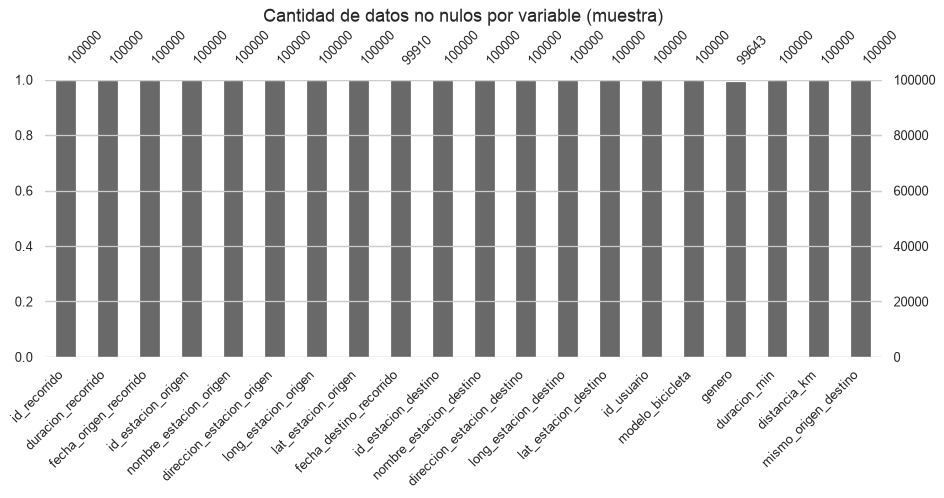

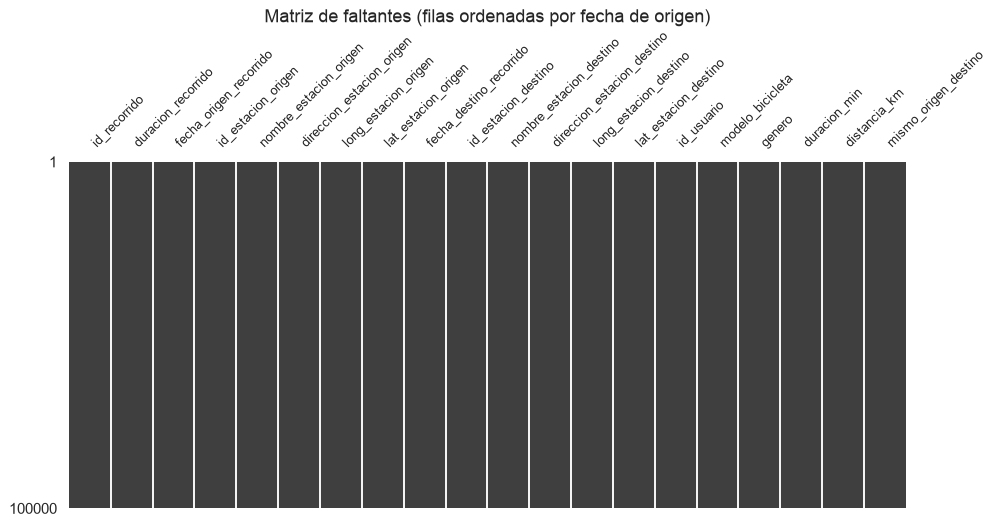

In [20]:
# Visualización con la biblioteca missingno (sobre una muestra: el dataset tiene 3,5 M de filas).
# Ordenamos la muestra por fecha para ver si los faltantes se concentran en algún período.
muestra_na = df.sample(100_000, random_state=SEED).sort_values('fecha_origen_recorrido')

msno.bar(muestra_na, fontsize=10, figsize=(12, 4))
plt.title("Cantidad de datos no nulos por variable (muestra)", fontsize=14)
plt.show()

msno.matrix(muestra_na, figsize=(12, 5), fontsize=10, sparkline=False)
plt.title("Matriz de faltantes (filas ordenadas por fecha de origen)", fontsize=14)
plt.show()

Con tan pocos faltantes (0,09% y 0,34%), en los gráficos de `missingno` casi no se ven: por eso el análisis de su causa lo hacemos con la función `nulos_por_grupo` de la clase 3, comparando el % de faltantes entre distintas "tajadas" del dataset.

También hay **faltantes "disfrazados"**: viajes con `duracion_recorrido = 0` (la duración no se registró realmente). Los analizamos junto con `fecha_destino`.

## 5.1 `fecha_destino_recorrido` (3.379 nulos, 0,09%)
Para saber si es MCAR, agrupamos de distintas maneras y vemos si el % de faltantes es parecido en todos los grupos (criterio de clase).

Nulos en 'fecha_destino_recorrido' por mes:
     mes  porcentaje_nulos_fecha_destino_recorrido
0     1                                     0.000
1     2                                     0.000
2     3                                     0.000
3     4                                     0.000
4     5                                     0.000
5     6                                     0.000
6     7                                     0.000
7     8                                     0.000
8     9                                     0.000
9    10                                     0.000
10   11                                     0.322
11   12                                     0.683 

Primer viaje sin fecha de destino: 2024-11-07 16:35:21
Duración de esos viajes: {'min': 0.0, 'max': 0.0}
Chi² faltante x mes: p-valor = 0.00e+00 | V de Cramér = 0.068


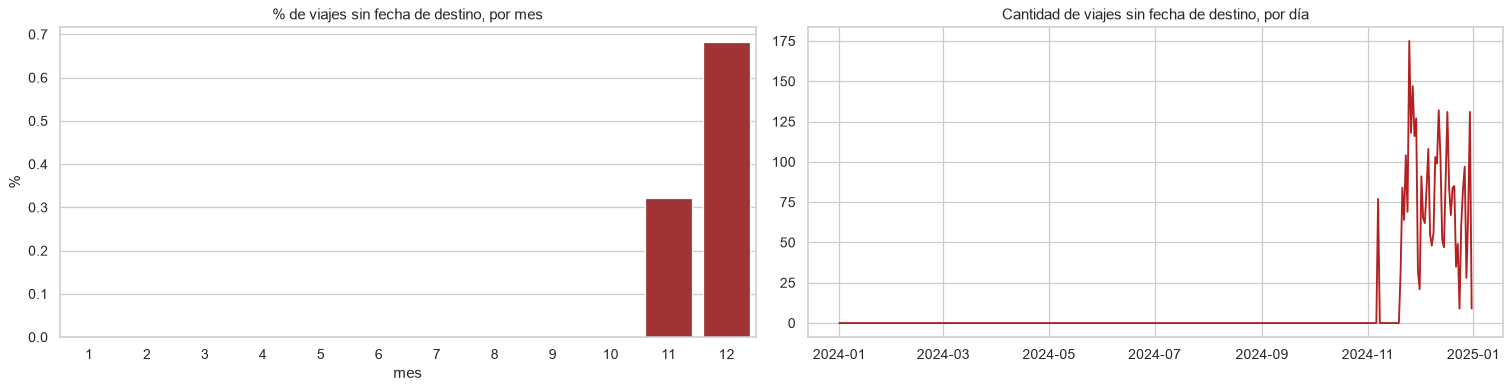

In [21]:
# Función de la clase 3: porcentaje de nulos en una columna, agrupando por una o más columnas
def nulos_por_grupo(df, grupo_cols, target_col):
    agrupar_nulos = (
        df.groupby(grupo_cols, observed=True)[target_col]
        .apply(lambda x: x.isnull().mean() * 100)
        .reset_index(name=f'porcentaje_nulos_{target_col}')
    )
    return agrupar_nulos

# Agregamos columnas auxiliares para "tajar" el dataset
df_aux = df[['fecha_origen_recorrido', 'fecha_destino_recorrido', 'duracion_recorrido',
             'genero', 'modelo_bicicleta', 'id_usuario']].copy()
df_aux['mes'] = df_aux['fecha_origen_recorrido'].dt.month
df_aux['dia_semana'] = df_aux['fecha_origen_recorrido'].dt.dayofweek
df_aux['franja_6h'] = (df_aux['fecha_origen_recorrido'].dt.hour // 6) * 6

nulos_fd_por_mes = nulos_por_grupo(df_aux, 'mes', 'fecha_destino_recorrido')
print("Nulos en 'fecha_destino_recorrido' por mes:\n", nulos_fd_por_mes, "\n")

falta_fd = df_aux['fecha_destino_recorrido'].isna()
print('Primer viaje sin fecha de destino:', df_aux.loc[falta_fd, 'fecha_origen_recorrido'].min())
print('Duración de esos viajes:', df_aux.loc[falta_fd, 'duracion_recorrido'].describe()[['min', 'max']].to_dict())

# Test chi² de independencia: ¿la falta depende del mes?
p = chi2_contingency(pd.crosstab(falta_fd, df_aux['mes']))[1]
print(f"Chi² faltante x mes: p-valor = {p:.2e} | V de Cramér = {cramers_v(falta_fd, df_aux['mes']):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
sns.barplot(data=nulos_fd_por_mes, x='mes', y='porcentaje_nulos_fecha_destino_recorrido', color='firebrick', ax=axes[0])
axes[0].set_title('% de viajes sin fecha de destino, por mes'); axes[0].set_ylabel('%')
falta_fd.groupby(df_aux['fecha_origen_recorrido'].dt.date).sum().plot(ax=axes[1], color='firebrick')
axes[1].set_title('Cantidad de viajes sin fecha de destino, por día'); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()

**Diagnóstico → MAR (no MCAR).**
- **Todos** los faltantes de `fecha_destino` aparecen **a partir del 7/11/2024** y solo en noviembre–diciembre; de enero a octubre hay 0. El % de faltantes **no** es parecido entre meses y el chi² rechaza la independencia → la falta **depende de una variable observada (la fecha)**: es **MAR**. La explicación más probable es un **cambio o falla del sistema de registro** a partir de esa fecha.
- Además, **todos** esos viajes tienen `duracion = 0`: el viaje no quedó "cerrado" en el sistema. No es que no sepamos la fecha: **no sabemos la duración, que es nuestra target**.
- *Corrección respecto del borrador:* lo habíamos llamado MCAR, pero el patrón temporal muestra que no lo es.

**Tratamiento:** se **eliminan** estas filas. Justificación: (1) son el 0,09% del total; (2) **no tienen target** (duración 0 no es un valor real) y un registro sin target no sirve para entrenar ni evaluar un modelo supervisado; (3) imputar la target sería inventar la respuesta.

## 5.2 `genero` (11.946 nulos, 0,34%)

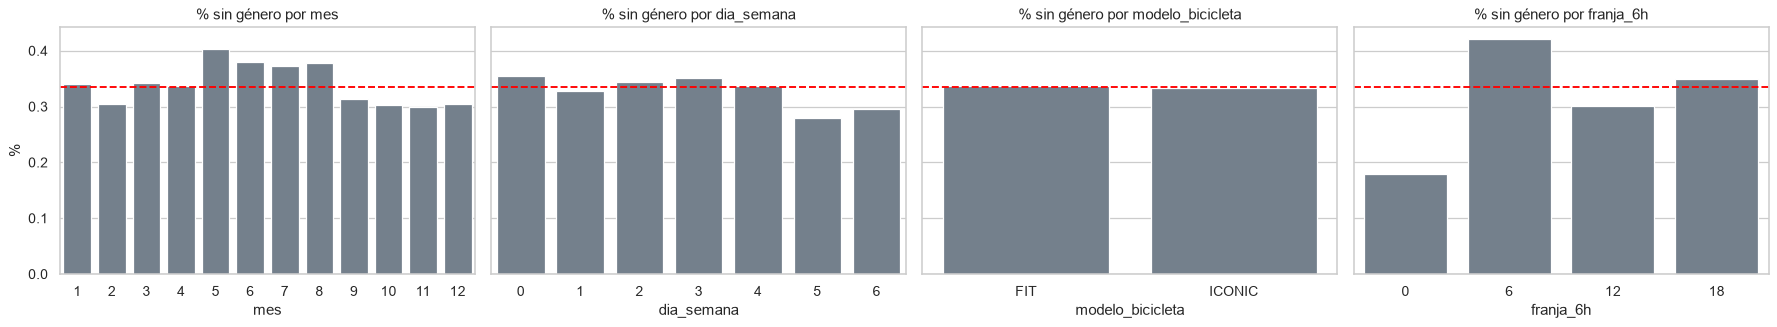

falta de género x mes               V de Cramér = 0.0059  (p-valor = 7.28e-21)
falta de género x dia_semana        V de Cramér = 0.0036  (p-valor = 4.28e-08)
falta de género x modelo_bicicleta  V de Cramér = 0.0003  (p-valor = 5.92e-01)
falta de género x franja_6h         V de Cramér = 0.0103  (p-valor = 4.55e-82)

Usuarios distintos con género faltante: 535
¿Alguno de esos usuarios tiene género informado en otro viaje? False


In [22]:
# ¿Son MCAR? Analizamos el porcentaje de faltantes para distintas "tajadas" del dataset.
# Si los porcentajes son similares, es probable que los datos sean MCAR.
nulos_genero_por_mes     = nulos_por_grupo(df_aux, 'mes', 'genero')
nulos_genero_por_dia     = nulos_por_grupo(df_aux, 'dia_semana', 'genero')
nulos_genero_por_modelo  = nulos_por_grupo(df_aux, 'modelo_bicicleta', 'genero')
nulos_genero_por_franja  = nulos_por_grupo(df_aux, 'franja_6h', 'genero')

fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, (tabla, col) in zip(axes, [(nulos_genero_por_mes, 'mes'), (nulos_genero_por_dia, 'dia_semana'),
                                   (nulos_genero_por_modelo, 'modelo_bicicleta'), (nulos_genero_por_franja, 'franja_6h')]):
    sns.barplot(data=tabla, x=col, y='porcentaje_nulos_genero', color='slategray', ax=ax)
    ax.axhline(df_aux['genero'].isna().mean() * 100, color='red', ls='--')
    ax.set_title(f'% sin género por {col}'); ax.set_ylabel('%')
plt.tight_layout(); plt.show()

falta_g = df_aux['genero'].isna()
for col in ['mes', 'dia_semana', 'modelo_bicicleta', 'franja_6h']:
    p = chi2_contingency(pd.crosstab(falta_g, df_aux[col]))[1]
    print(f'falta de género x {col:17s} V de Cramér = {cramers_v(falta_g, df_aux[col]):.4f}  (p-valor = {p:.2e})')

usuarios_sin_genero = df_aux.loc[falta_g, 'id_usuario'].unique()
print(f'\nUsuarios distintos con género faltante: {len(usuarios_sin_genero)}')
print('¿Alguno de esos usuarios tiene género informado en otro viaje?',
      df_aux.loc[df_aux['id_usuario'].isin(usuarios_sin_genero), 'genero'].notna().any())

**Diagnóstico → MCAR respecto de las variables del viaje (aprox.), con origen en el perfil del usuario.**
- El % de faltantes es **prácticamente igual** en todos los meses, días, modelos y franjas horarias (≈0,3%) y las V de Cramér son ≈ 0: la falta **no depende** de las características del viaje → se comporta como **MCAR**. (Los p-valores pueden dar "significativos" por el enorme n, pero el tamaño del efecto es despreciable.)
- Los faltantes corresponden a **535 usuarios que nunca informaron su género** (ninguno lo tiene en otro viaje). Es un dato que falta **a nivel usuario** (perfil incompleto), no un error al azar de cada viaje. No hay evidencia de MNAR.

**Tratamiento (sección 10):** como es una categórica con muy baja cantidad de faltantes (<10%), según la tabla de la clase 5 podríamos eliminar filas o imputar con la moda / nueva categoría. Elegimos **crear la categoría `NO_INFORMADO`**: no perdemos los viajes de esos usuarios y no inventamos un género (imputar `MALE` por moda sería asignarle un valor falso al 100% de los viajes de 535 personas).

# 6. Outliers y errores
Distinguimos dos cosas (clase 4: *"analizar si se trata de errores o son valores legítimos"*):
1. **Errores / registros inválidos** → se eliminan en la limpieza.
2. **Valores extremos legítimos** → se tratan (capping) después del split.

## 6.1 Detección estadística: IQR (robusto) y media ± 3σ (clásico)

In [23]:
# Método del rango intercuartil: un dato es outlier si es < (Q1 - 1.5*IQR) o > (Q3 + 1.5*IQR)
columnas = ['duracion_min', 'distancia_km', 'lat_estacion_origen', 'long_estacion_origen']
df_outliers = df[columnas]

Q1 = df_outliers.quantile(0.25)
Q3 = df_outliers.quantile(0.75)
IQR = Q3 - Q1
outliers_iqr = (df_outliers < (Q1 - 1.5 * IQR)) | (df_outliers > (Q3 + 1.5 * IQR))

# Diccionario con los límites inferior y superior de cada variable
outlier_limits = {col: (Q1[col] - 1.5 * IQR[col], Q3[col] + 1.5 * IQR[col]) for col in columnas}
for col in columnas:
    print(f"{col:22s}: <{outlier_limits[col][0]:.2f} o >{outlier_limits[col][1]:.2f}  -> {outliers_iqr[col].sum():,} outliers")

duracion_min          : <-16.31 o >49.09  -> 197,787 outliers
distancia_km          : <-1.78 o >5.39  -> 139,836 outliers
lat_estacion_origen   : <-34.67 o >-34.53  -> 17,843 outliers
long_estacion_origen  : <-58.53 o >-58.31  -> 0 outliers


duracion_min          : <-457.96 o >500.46  -> 2,420 outliers
distancia_km          : <-2.82 o >6.75  -> 51,760 outliers
lat_estacion_origen   : <-34.67 o >-34.53  -> 17,843 outliers
long_estacion_origen  : <-58.54 o >-58.31  -> 0 outliers


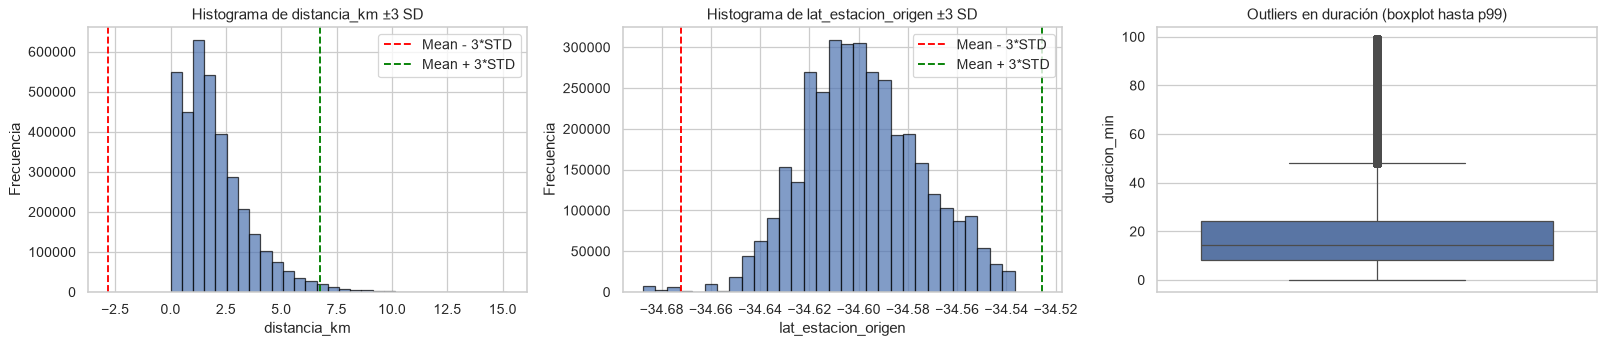

In [24]:
# Método basado en la desviación estándar (asume distribución normal): < media - 3*std o > media + 3*std
mean = df_outliers.mean()
std = df_outliers.apply(lambda x: np.nanstd(x, ddof=1))
outliers_std = (df_outliers < (mean - 3 * std)) | (df_outliers > (mean + 3 * std))
for col in columnas:
    print(f"{col:22s}: <{mean[col] - 3 * std[col]:.2f} o >{mean[col] + 3 * std[col]:.2f}  -> {outliers_std[col].sum():,} outliers")

def plot_hist_with_std(ax, data, varname, mean, std):
    ax.hist(data, bins=30, edgecolor='black', alpha=0.7)
    ax.axvline(mean[varname] - 3*std[varname], color='red', linestyle='--', label='Mean - 3*STD')
    ax.axvline(mean[varname] + 3*std[varname], color='green', linestyle='--', label='Mean + 3*STD')
    ax.set_xlabel(varname)
    ax.set_ylabel('Frecuencia')
    ax.set_title(f'Histograma de {varname} ±3 SD')
    ax.legend()

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
plot_hist_with_std(ax[0], df['distancia_km'], 'distancia_km', mean, std)
plot_hist_with_std(ax[1], df['lat_estacion_origen'], 'lat_estacion_origen', mean, std)
# Boxplot de la duración (hasta el p99 para que se vea la caja)
sns.boxplot(y=df.loc[df['duracion_min'] <= df['duracion_min'].quantile(.99), 'duracion_min'], ax=ax[2])
ax[2].set_title('Outliers en duración (boxplot hasta p99)')
plt.tight_layout(); plt.show()

- **Duración:** el método IQR marca como outliers los viajes de más de ~49 min (≈198 mil viajes, 5,6%). El método de 3σ da un límite absurdo (≈ 8 horas) porque la media y el desvío están inflados por los extremos y además **asume normalidad**, que acá no se cumple → **el IQR es más adecuado**.
- **Latitud / distancia:** los "outliers" son estaciones reales del extremo sur de la ciudad o viajes largos legítimos (se ven en el mapa de la sección 3.4) → **no son errores, se conservan**.

## 6.2 Análisis de errores en la duración (con conocimiento del dominio)

In [25]:
d = df['duracion_min']
mismo = df['mismo_origen_destino'] == 1
# Tramos de duración (en minutos). Los viajes de más de 1 hora se abren en subcategorías:
# 1-3 h, 3-6 h, 6-12 h, 12-24 h y más de 24 h
CORTES_TRAMOS = [-0.01, 0, 1, 2, 5, 10, 60, 3 * 60, 6 * 60, 12 * 60, 24 * 60, np.inf]
ETIQ_TRAMOS = ['0', '(0,1] min', '(1,2] min', '(2,5] min', '(5,10] min', '(10,60] min',
               '(1,3] h', '(3,6] h', '(6,12] h', '(12,24] h', '> 24 h']
tramos = pd.cut(d, CORTES_TRAMOS, labels=ETIQ_TRAMOS)
tabla_tramos = pd.crosstab(tramos, mismo.map({True: 'Origen = destino', False: 'Origen ≠ destino'}), margins=True)
tabla_tramos['% del total'] = tabla_tramos['All'] / len(df) * 100
tabla_tramos

mismo_origen_destino,Origen = destino,Origen ≠ destino,All,% del total
duracion_min,,,,
0,6211,31407,37618,1.057
"(0,1] min",227029,60387,287416,8.075
"(1,2] min",25568,1340,26908,0.756
"(2,5] min",24655,118111,142766,4.011
"(5,10] min",17210,641276,658486,18.501
"(10,60] min",151128,2138150,2289278,64.319
"(1,3] h",24986,79980,104966,2.949
"(3,6] h",1894,5995,7889,0.222
"(6,12] h",453,1960,2413,0.068


### 6.2.1 Viajes largos: ¿paseos reales o errores?
Para los viajes de más de 1 hora no alcanza con la duración: miramos **cuándo empiezan, cuándo terminan, si cruzan la medianoche, si son de fin de semana y si vuelven a la misma estación**. Si fueran paseos, deberían parecerse a un uso recreativo de día. Si la bici quedó "retenida" (el usuario se la llevó a su casa, no la ancló bien, la dejó estacionada), deberían empezar a la tarde-noche y terminar a la mañana siguiente.

,viajes,% del total de viajes,% cruza la medianoche,% fin de semana,% origen = destino,hora de inicio (mediana),hora de fin (mediana)
tramo,,,,,,,
"(1,3] h",104966,2.950,3.550,40.800,23.800,16.000,17.000
"(3,6] h",7889,0.220,13.180,33.440,24.010,14.000,17.000
"(6,12] h",2413,0.070,46.870,23.170,18.770,15.000,9.000
"(12,24] h",856,0.020,85.860,17.990,16.590,18.000,12.000
> 24 h,687,0.020,100.000,16.160,7.420,16.000,14.000


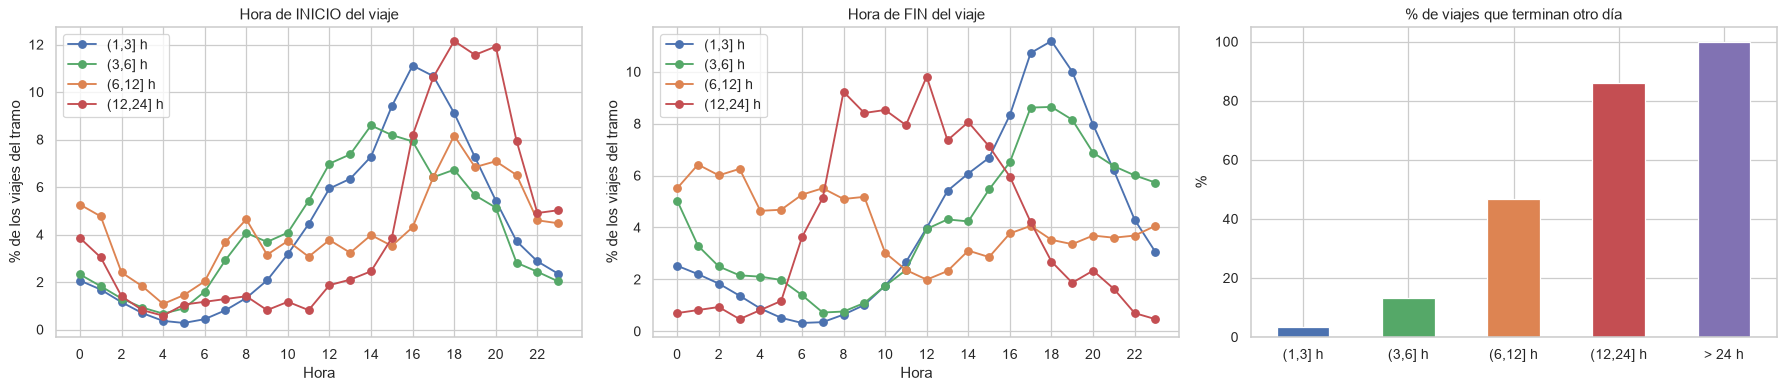

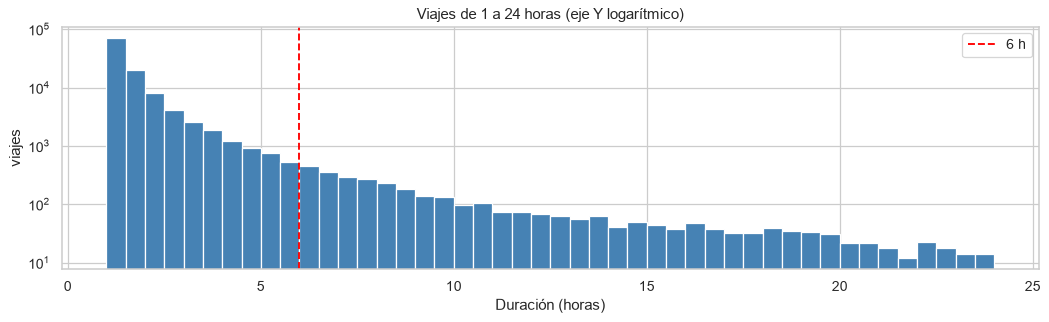

In [26]:
largos = df[d > 60].copy()
largos['tramo'] = pd.cut(largos['duracion_min'], [60, 3 * 60, 6 * 60, 12 * 60, 24 * 60, np.inf],
                         labels=['(1,3] h', '(3,6] h', '(6,12] h', '(12,24] h', '> 24 h'])
largos['hora_inicio'] = largos['fecha_origen_recorrido'].dt.hour
largos['hora_fin'] = largos['fecha_destino_recorrido'].dt.hour
largos['cruza_medianoche'] = largos['fecha_origen_recorrido'].dt.date != largos['fecha_destino_recorrido'].dt.date
largos['fin_de_semana'] = largos['fecha_origen_recorrido'].dt.dayofweek >= 5

g = largos.groupby('tramo', observed=True)
perfil = pd.DataFrame({
    'viajes': g.size(),
    '% del total de viajes': g.size() / len(df) * 100,
    '% cruza la medianoche': g['cruza_medianoche'].mean() * 100,
    '% fin de semana': g['fin_de_semana'].mean() * 100,
    '% origen = destino': g['mismo_origen_destino'].mean() * 100,
    'hora de inicio (mediana)': g['hora_inicio'].median(),
    'hora de fin (mediana)': g['hora_fin'].median(),
})
display(perfil.round(2))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for tramo, color in zip(['(1,3] h', '(3,6] h', '(6,12] h', '(12,24] h'], ['#4C72B0', '#55A868', '#DD8452', '#C44E52']):
    sub = largos[largos['tramo'] == tramo]
    axes[0].plot(sub['hora_inicio'].value_counts(normalize=True).sort_index() * 100, marker='o', label=tramo, color=color)
    axes[1].plot(sub['hora_fin'].value_counts(normalize=True).sort_index() * 100, marker='o', label=tramo, color=color)
for ax, t in zip(axes[:2], ['Hora de INICIO del viaje', 'Hora de FIN del viaje']):
    ax.set_title(t); ax.set_xlabel('Hora'); ax.set_ylabel('% de los viajes del tramo'); ax.set_xticks(range(0, 24, 2)); ax.legend()
perfil['% cruza la medianoche'].plot.bar(ax=axes[2], color=['#4C72B0', '#55A868', '#DD8452', '#C44E52', '#8172B3'])
axes[2].set_title('% de viajes que terminan otro día'); axes[2].set_ylabel('%'); axes[2].set_xlabel(''); axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# ¿Hay un "corte natural" en la distribución? Viajes por media hora entre 1 y 24 h
plt.figure(figsize=(14, 3.5))
plt.hist(largos.loc[largos['duracion_min'] <= 24 * 60, 'duracion_min'] / 60, bins=np.arange(1, 24.5, 0.5), color='steelblue')
plt.yscale('log'); plt.axvline(6, color='red', ls='--', label='6 h')
plt.title('Viajes de 1 a 24 horas (eje Y logarítmico)'); plt.xlabel('Duración (horas)'); plt.ylabel('viajes'); plt.legend()
plt.show()

Viajes con velocidad implícita > 25 km/h: 60660


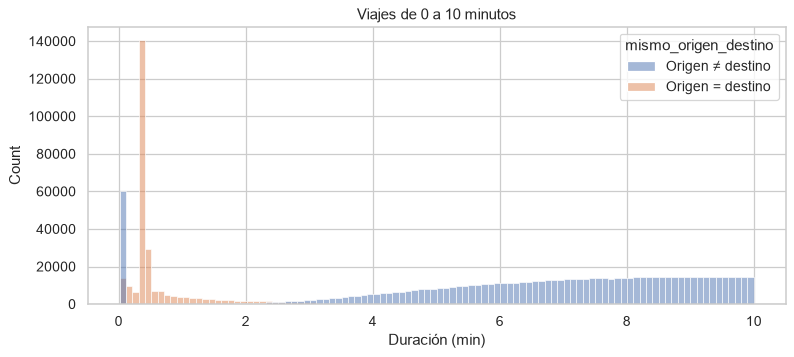

In [27]:
# velocidad implícita: distancia en línea recta / tiempo (solo para detectar errores, NO es un feature: usa la target)
vel = df['distancia_km'] / (df['duracion_recorrido'] / 3600)
print('Viajes con velocidad implícita > 25 km/h:', ((vel > 25) & np.isfinite(vel)).sum())

fig, ax = plt.subplots(figsize=(10, 4))
corta = df[(d > 0) & (d <= 10)]
sns.histplot(data=corta, x='duracion_min', hue=corta['mismo_origen_destino'].map({1: 'Origen = destino', 0: 'Origen ≠ destino'}),
             bins=100, ax=ax)
ax.set_title('Viajes de 0 a 10 minutos'); ax.set_xlabel('Duración (min)')
plt.show()

**Hallazgos (registros que consideramos errores o "no viajes"):**
| Caso | Cantidad aprox. | Interpretación | Decisión |
|---|---|---|---|
| Duración = 0 | 37,6 mil | No se registró la duración (incluye los 3.379 sin fecha de destino) | Eliminar |
| Origen = destino y duración ≤ 2 min | ~250 mil | El usuario saca la bici y la devuelve enseguida (bici con falla, arrepentimiento). No es un viaje | Eliminar |
| Velocidad implícita > 25 km/h | decenas de miles | Físicamente imposible en bici urbana (ej.: 2 km en 30 s) → error de registro | Eliminar |
| (1, 3] h | ~105 mil (3%) | Uso recreativo: 41% de fin de semana, 24% vuelve a la misma estación, empieza a la tarde y termina el mismo día → **paseos reales** | Mantener (capping en sección 11) |
| (3, 6] h | ~7.900 (0,2%) | Todavía parecido a un paseo largo con paradas: empieza a media tarde (mediana 14 h), termina a la tarde (mediana 17 h), solo 13% cruza la medianoche → **extremo pero posible** | Mantener (capping en sección 11) |
| (6, 12] h | ~2.400 (0,07%) | Cambia el patrón: empieza a la tarde-noche (las horas más frecuentes son 18–21 h) y termina de madrugada o a la mañana (mediana 9 h); 47% cruza la medianoche → la bici quedó **retenida** (en casa, mal anclada) | Eliminar |
| (12, 24] h | ~860 (0,02%) | Empieza a la tarde-noche y se devuelve a la mañana siguiente; 86% cruza la medianoche → **retención nocturna** | Eliminar |
| > 24 h | ~690 (0,02%) | Bici no devuelta durante días / falla del sistema | Eliminar |

El pico de viajes de < 2 min es casi todo de origen = destino, lo que confirma la interpretación de "devolución inmediata".

**Sobre los viajes largos, una distinción importante:** la duración registrada no es *tiempo pedaleando*, es *tiempo que la bici estuvo fuera del anclaje*. Por eso un viaje de 8 horas no es necesariamente un error **de registro**: muy probablemente las fechas son correctas y la persona se llevó la bici a su casa. Lo que sí es claro es que **no representa un viaje en bicicleta**, que es lo que queremos predecir. Lo eliminamos por estar **fuera del alcance del problema**, no por ser un dato falso.

**¿Por qué el corte en 6 horas?** La distribución decrece en forma continua, sin un salto natural: cualquier umbral es una decisión de criterio, y hay que justificarla. Elegimos 6 h porque es donde **cambia el comportamiento**: hasta 6 h los viajes terminan a la tarde del mismo día (patrón de paseo); desde 6 h terminan de madrugada o a la mañana siguiente (el % que cruza la medianoche salta de 13% a 47% y luego a 86%). La regla de dominio ("nadie pedalea más de 6 horas seguidas") coincide con lo que muestran los datos.

# 7. Planteo del problema de ML supervisado

**Escenario:** un usuario retira una bicicleta e indica a qué estación se dirige. Queremos **predecir cuánto va a durar el viaje**. Utilidad: estimar cuándo se liberará una bici / anclaje en la estación de destino, planificar la redistribución de bicicletas, avisar al usuario el tiempo estimado.

- **Tipo de problema:** **regresión** (la etiqueta es una cantidad).
- **Variable target:** `duracion_min` = duración del viaje en minutos.
- **¿Por qué regresión y no clasificación?** La duración es continua y el escenario pide estimar minutos. Convertirla en clases (ej.: corto/medio/largo) perdería información y obligaría a elegir cortes arbitrarios.

**Features candidatas** (información disponible **al momento de retirar la bici**):
- Espaciales: estación de origen y de destino, sus coordenadas, **distancia** entre ellas, si vuelve a la misma estación.
- Temporales: hora, día de la semana, mes, fin de semana, feriado, hora pico.
- Usuario y bici: género, modelo de bicicleta, frecuencia de uso del usuario.

**Excluidas:**
| Columna | Motivo |
|---|---|
| `fecha_destino_recorrido` | **Leakage**: duración = destino − origen. No se conoce al retirar la bici |
| `duracion_recorrido` | Es la target (en segundos) |
| `id_recorrido` | Identificador sin información (cardinalidad extrema) |
| `nombre_*`, `direccion_*` | Redundantes con `id_estacion_*` (relación 1 a 1) |
| `id_usuario` (crudo) | Cardinalidad muy alta; no entra como tal: se codifica con *frequency encoding* (sección 14) |

# 8. Limpieza general del dataset
Esta limpieza se hace **antes del split** porque son reglas **fijas, fila por fila** (no se calcula nada a partir de otras observaciones), por lo que no generan leakage: eliminamos registros que no son viajes válidos en cualquier conjunto.

In [28]:
n0 = len(df)
vel = df['distancia_km'] / (df['duracion_recorrido'] / 3600)

reglas = {
    'Sin fecha de destino (target faltante)': df['fecha_destino_recorrido'].isna(),
    'Duración = 0': df['duracion_recorrido'] == 0,
    'Devolución inmediata (origen = destino y ≤ 2 min)': (df['mismo_origen_destino'] == 1) & (df['duracion_min'] <= 2),
    'Velocidad imposible (> 25 km/h)': (vel > 25) & np.isfinite(vel),
    'Duración > 6 h (bici retenida o no devuelta, ver 6.2.1)': df['duracion_min'] > 6 * 60,
}
a_borrar = pd.Series(False, index=df.index)
embudo = []
for nombre, regla in reglas.items():
    nuevas = regla & ~a_borrar
    embudo.append({'regla': nombre, 'filas eliminadas (nuevas)': nuevas.sum()})
    a_borrar |= regla
embudo = pd.DataFrame(embudo)
embudo.loc[len(embudo)] = ['TOTAL', a_borrar.sum()]
embudo['% del total'] = embudo['filas eliminadas (nuevas)'] / n0 * 100
display(embudo)

df = df[~a_borrar].copy()

# Eliminamos columnas irrelevantes / redundantes / con leakage
cols_drop = ['id_recorrido', 'duracion_recorrido', 'fecha_destino_recorrido',
             'nombre_estacion_origen', 'direccion_estacion_origen',
             'nombre_estacion_destino', 'direccion_estacion_destino']
df = df.drop(columns=cols_drop).reset_index(drop=True)
print(f'Filas: {n0:,} -> {len(df):,}  ({len(df)/n0:.1%} conservado)')
print('Columnas restantes:', df.columns.tolist())

,regla,filas eliminadas (nuevas),% del total
0,Sin fecha de destino (target faltante),3379,0.095
1,Duración = 0,34239,0.962
2,Devolución inmediata (origen = destino y ≤ 2 min),252597,7.097
3,Velocidad imposible (> 25 km/h),60660,1.704
4,"Duración > 6 h (bici retenida o no devuelta, v...",3956,0.111
5,TOTAL,354831,9.969


Filas: 3,559,283 -> 3,204,452  (90.0% conservado)
Columnas restantes: ['fecha_origen_recorrido', 'id_estacion_origen', 'long_estacion_origen', 'lat_estacion_origen', 'id_estacion_destino', 'long_estacion_destino', 'lat_estacion_destino', 'id_usuario', 'modelo_bicicleta', 'genero', 'duracion_min', 'distancia_km', 'mismo_origen_destino']


**Resultado:** se eliminaron 354.831 registros (10,0%) y se conservan 3.204.452 viajes (90,0%). Lo eliminado son registros que no representan un viaje real o que no tienen target. Con más de 3 millones de filas restantes, la pérdida no compromete el análisis.

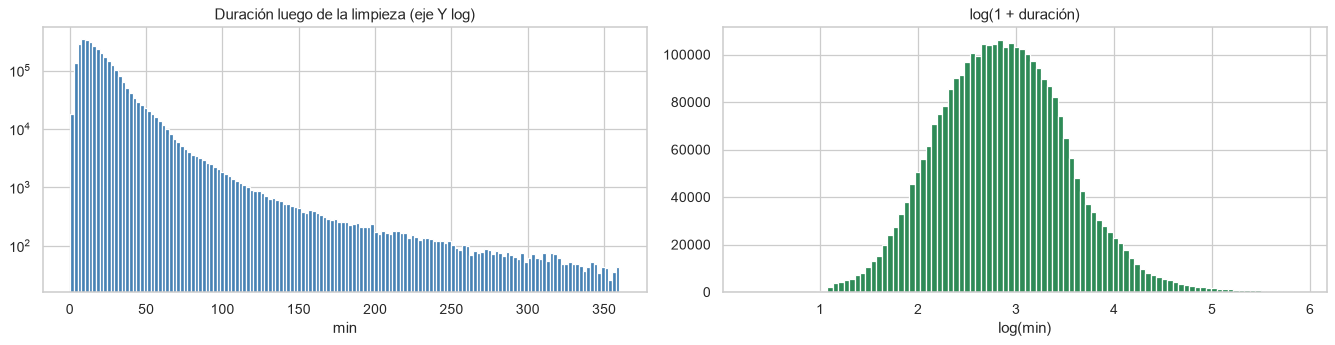

Asimetría: original = 5.24 | log = 0.32


In [29]:
# Distribución de la target después de la limpieza
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].hist(df['duracion_min'], bins=150, color='steelblue'); axes[0].set_yscale('log')
axes[0].set_title('Duración luego de la limpieza (eje Y log)'); axes[0].set_xlabel('min')
axes[1].hist(np.log1p(df['duracion_min']), bins=100, color='seagreen')
axes[1].set_title('log(1 + duración)'); axes[1].set_xlabel('log(min)')
plt.tight_layout(); plt.show()
print(f"Asimetría: original = {df['duracion_min'].skew():.2f} | log = {np.log1p(df['duracion_min']).skew():.2f}")

La transformación **logarítmica** vuelve la distribución mucho más simétrica. Queda como opción para el modelo (predecir `log(duración)`), útil para modelos lineales que son sensibles a la asimetría y a los extremos.

## 8.1 Cruce: día de la semana × duración del viaje
Con los datos ya limpios cruzamos el día de la semana con la duración. Usamos **mediana y cuartiles** (la duración es asimétrica), el **% de viajes largos** y la **distancia mediana**, para ver si los viajes del fin de semana son más largos porque se va más lejos o porque se usa la bici de otra forma.

,viajes,% de los viajes,Q1 (min),mediana (min),Q3 (min),media (min),% > 30 min,% > 60 min,distancia mediana (km)
Lun,529466,16.500,9.500,15.200,24.200,19.700,15.300,2.600,1.700
Mar,568733,17.700,9.600,15.200,23.900,19.400,14.600,2.300,1.700
Mié,561657,17.500,9.600,15.300,24.000,19.400,14.600,2.300,1.700
Jue,578104,18.000,9.700,15.400,24.100,19.600,14.800,2.300,1.800
Vie,546389,17.100,9.700,15.500,24.400,19.900,15.400,2.600,1.700
Sáb,212855,6.600,14.000,24.100,40.000,31.500,38.500,9.900,1.900
Dom,207248,6.500,15.400,26.500,43.200,34.000,43.000,11.700,1.900


eta² (día de la semana -> duración): 0.047
Mediana días hábiles: 15.3 min | fin de semana: 25.3 min


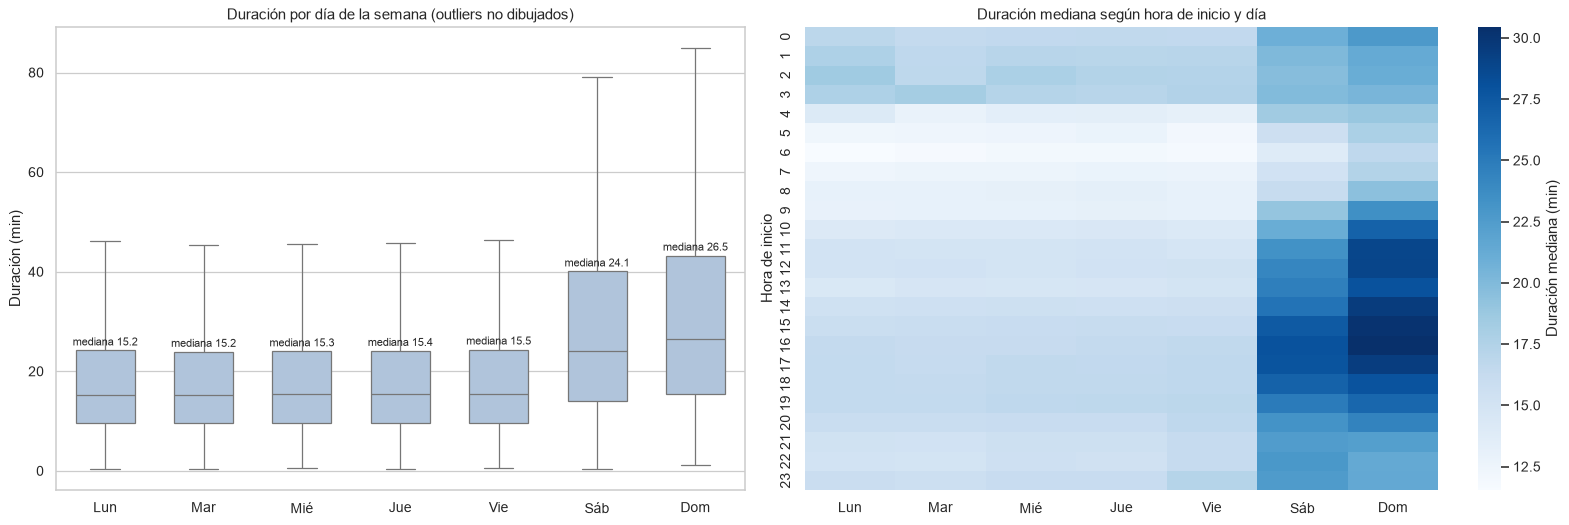

In [30]:
dias_lista = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
dow = df['fecha_origen_recorrido'].dt.dayofweek
g = df.groupby(dow)
cruce = pd.DataFrame({
    'viajes': g.size(),
    '% de los viajes': g.size() / len(df) * 100,
    'Q1 (min)': g['duracion_min'].quantile(.25),
    'mediana (min)': g['duracion_min'].median(),
    'Q3 (min)': g['duracion_min'].quantile(.75),
    'media (min)': g['duracion_min'].mean(),
    '% > 30 min': g['duracion_min'].apply(lambda s: (s > 30).mean() * 100),
    '% > 60 min': g['duracion_min'].apply(lambda s: (s > 60).mean() * 100),
    'distancia mediana (km)': g['distancia_km'].median(),
})
cruce.index = dias_lista
display(cruce.round(1))

print(f"eta² (día de la semana -> duración): {eta_squared(df['duracion_min'], dow)[0]:.3f}")
finde = dow >= 5
print(f"Mediana días hábiles: {df.loc[~finde, 'duracion_min'].median():.1f} min | fin de semana: {df.loc[finde, 'duracion_min'].median():.1f} min")

mapa = df.pivot_table(index=df['fecha_origen_recorrido'].dt.hour, columns=dow, values='duracion_min', aggfunc='median')
mapa.columns = dias_lista

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 1.15]})
sns.boxplot(x=dow.map(dict(enumerate(dias_lista))), y=df['duracion_min'], order=dias_lista,
            showfliers=False, ax=axes[0], color='#A9C4E2', width=.6)
for i, v in enumerate(cruce['mediana (min)']):
    axes[0].text(i, cruce['Q3 (min)'].iloc[i] + 1, f'mediana {v:.1f}', ha='center', fontsize=9)
axes[0].set_title('Duración por día de la semana (outliers no dibujados)')
axes[0].set_xlabel(''); axes[0].set_ylabel('Duración (min)')
sns.heatmap(mapa, cmap='Blues', ax=axes[1], cbar_kws={'label': 'Duración mediana (min)'})
axes[1].set_title('Duración mediana según hora de inicio y día'); axes[1].set_xlabel(''); axes[1].set_ylabel('Hora de inicio')
plt.tight_layout(); plt.show()

**Interpretación:**
- **De lunes a viernes la duración es casi idéntica**: mediana ≈ 15 min, Q1–Q3 ≈ 10–24 min y ~15% de viajes de más de 30 min.
- **El fin de semana los viajes son mucho más largos**: mediana de 24 min el sábado y 26,5 min el domingo (+60–70%), y el % de viajes de más de 30 min casi se triplica (38–43%).
- La **distancia mediana casi no cambia** (1,7 km en días hábiles vs. 1,9 km el fin de semana). Los viajes no son más largos porque se va más lejos, sino porque **se va más lento o con paradas**: uso recreativo (paseo) en vez de traslado.
- El mapa de calor lo confirma: en días hábiles los viajes de la mañana (6–9 h, ida al trabajo) son los más cortos (~12–13 min). Sábado y domingo entre las 10 y las 18 h superan los 25–30 min.
- El día explica ≈ 4,7% de la variabilidad de la duración (eta²): es un efecto **pequeño pero el mayor entre las variables temporales**. Por eso conviene `es_fin_de_semana` como feature, y además su **interacción con la hora** (un modelo de árboles la captura sola).

# 9. Split del dataset (train / test)
Como en la clase 4, separamos primero las **features (X)** de la **target (y)** y hacemos el split con `train_test_split`:
- Proporción **80 / 20**.
- **Estratificado por tramos de duración** (≤15, 15–30, 30–60 y >60 min). En regresión no hay clases, pero estratificar por tramos de la target garantiza que la distribución de la duración —incluida su cola de viajes largos— quede igual en train y test. Los tramos se usan **solo para el split**.
- ¿Por qué no un split temporal? El objetivo no es pronosticar una serie, sino estimar la duración de un viaje a partir de sus características. (Un split temporal —entrenar ene–oct y testear nov–dic— sería una alternativa válida.)

**A partir de acá, todo lo que se calcula se calcula en TRAIN y se aplica en TEST.**

In [31]:
TARGET = 'duracion_min'

X = df.drop(columns=[TARGET])
y = df[TARGET]

CORTES = [0, 15, 30, 60, np.inf]
TRAMOS = ['≤15 min', '15-30 min', '30-60 min', '>60 min']
estrato = pd.cut(y, bins=CORTES, labels=TRAMOS)   # solo para estratificar el split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 80% entrenamiento, 20% test
    random_state=42,     # semilla para reproducibilidad
    shuffle=True,        # mezclar antes de hacer el split
    stratify=estrato     # misma proporción de tramos de duración en train y test
)
X_train, X_test = X_train.copy(), X_test.copy()
del df, X  # liberamos memoria

print("Verificamos el split 80-20")
print(f"Dataset completo : {len(y):,} filas")
print(f"X_train          : {X_train.shape[0]:,} filas, {X_train.shape[1]} columnas  ({X_train.shape[0]/len(y):.0%})")
print(f"X_test           : {X_test.shape[0]:,} filas, {X_test.shape[1]} columnas  ({X_test.shape[0]/len(y):.0%})")
print(f"y_train          : {y_train.shape[0]:,} filas")
print(f"y_test           : {y_test.shape[0]:,} filas")

display(pd.DataFrame({'train %': pd.cut(y_train, CORTES, labels=TRAMOS).value_counts(normalize=True) * 100,
                      'test %':  pd.cut(y_test,  CORTES, labels=TRAMOS).value_counts(normalize=True) * 100}).round(2))
pd.DataFrame({'y_train': y_train.describe(), 'y_test': y_test.describe()}).round(2)

Verificamos el split 80-20
Dataset completo : 3,204,452 filas
X_train          : 2,563,561 filas, 12 columnas  (80%)
X_test           : 640,891 filas, 12 columnas  (20%)
y_train          : 2,563,561 filas
y_test           : 640,891 filas


,train %,test %
duracion_min,,
≤15 min,45.800,45.800
15-30 min,35.880,35.880
30-60 min,14.800,14.800
>60 min,3.520,3.520


,y_train,y_test
count,"2,563,561.000","640,891.000"
mean,21.310,21.300
std,20.530,20.430
min,0.330,0.330
25%,10.000,10.020
50%,16.200,16.200
75%,25.920,25.920
max,359.900,359.930


# 10. Tratamiento de valores faltantes
Luego de la limpieza, el único faltante es `genero`. Aplicamos la decisión de la sección 5.2: **imputación con una constante**, creando la nueva categoría `NO_INFORMADO` (misma regla en train y test).

In [32]:
# Columnas con datos faltantes
print('X_train:\n', X_train.isna().sum()[X_train.isna().sum() > 0])
print('X_test:\n', X_test.isna().sum()[X_test.isna().sum() > 0])

# Imputación con una constante: nueva categoría (como la columna es 'category', primero agregamos la categoría)
for X_ in (X_train, X_test):
    X_['genero'] = X_['genero'].cat.add_categories('NO_INFORMADO')
    X_.fillna({'genero': 'NO_INFORMADO'}, inplace=True)

print('\nNulos totales después -> X_train:', X_train.isna().sum().sum(), '| X_test:', X_test.isna().sum().sum())
X_train['genero'].value_counts(normalize=True).mul(100).round(2)

X_train:
 genero    8824
dtype: int64
X_test:
 genero    2195
dtype: int64

Nulos totales después -> X_train: 0 | X_test: 0


genero
MALE           60.780
FEMALE         31.610
OTHER           7.270
NO_INFORMADO    0.340
Name: proportion, dtype: float64

# 11. Tratamiento de outliers
Los errores ya se eliminaron en la limpieza. Quedan **valores extremos legítimos** en la target (viajes de varias horas). Estrategias vistas en clase: eliminación, transformación logarítmica, imputación con valores estadísticos, **capping/winsorización** y segmentación.

**Elegimos capping en el percentil 99 calculado en TRAIN.** Justificación:
- No son errores, así que no los eliminamos (perderíamos información de que "ese viaje fue muy largo").
- Pero unos pocos viajes de varias horas dominarían una función de pérdida como el error cuadrático.
- El capping conserva la fila y su orden ("fue de los más largos") y limita su peso.
- El umbral (p99) se calcula **solo en train** y se aplica igual en test.

Sobre las features: la `distancia_km` tiene outliers por IQR pero son viajes reales y acotados, por lo que no se tratan.

Umbral de capping (p99 de train): 98.6 min
Viajes afectados -> train: 25,630 | test: 6,425


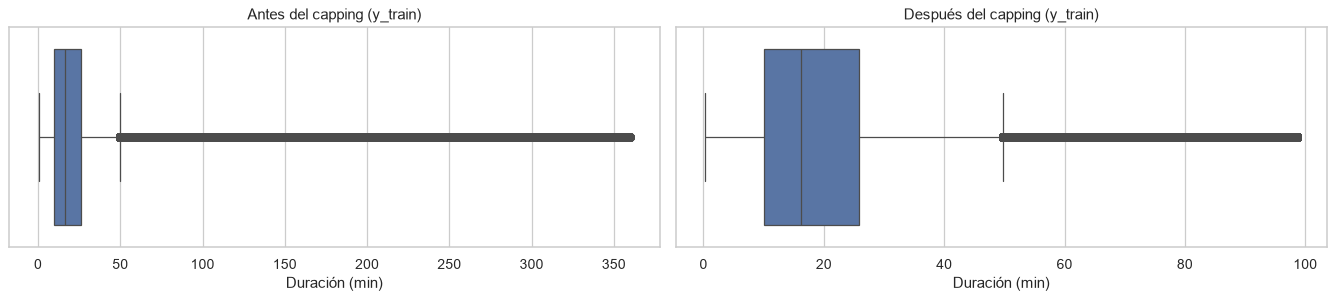

,original,con capping
count,"2,563,561.000","2,563,561.000"
mean,21.310,20.750
std,20.530,16.360
min,0.330,0.330
25%,10.000,10.000
50%,16.200,16.200
75%,25.920,25.920
max,359.900,98.630


In [33]:
umbral_p99 = y_train.quantile(0.99)   # CALCULAR en train
print(f'Umbral de capping (p99 de train): {umbral_p99:.1f} min')
print(f"Viajes afectados -> train: {(y_train > umbral_p99).sum():,} | test: {(y_test > umbral_p99).sum():,}")

y_train_original = y_train.copy()     # copia para comparar
y_train = y_train.clip(upper=umbral_p99)   # APLICAR en train
y_test  = y_test.clip(upper=umbral_p99)    # APLICAR en test

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
sns.boxplot(x=y_train_original, ax=axes[0]); axes[0].set_title('Antes del capping (y_train)')
sns.boxplot(x=y_train, ax=axes[1]); axes[1].set_title('Después del capping (y_train)')
for ax in axes: ax.set_xlabel('Duración (min)')
plt.tight_layout(); plt.show()

pd.DataFrame({'original': y_train_original.describe(), 'con capping': y_train.describe()}).round(2)

# 12. Feature engineering: creación de nuevos features (clase 5)
| Feature | Técnica | Justificación |
|---|---|---|
| `distancia_km` | Matemática (haversine con lat/lon) | El tiempo de viaje depende sobre todo de la distancia. Resume 4 coordenadas en 1 valor con significado (como el IMC en clase) |
| `mismo_origen_destino` | Comparación A = B | Los viajes que vuelven a la misma estación son paseos: la distancia es 0 pero la duración no |
| `hora`, `dia_semana`, `mes` | Temporal (extraer de timestamp) | Vimos patrones fuertes por hora, día y estación del año |
| `es_fin_de_semana`, `es_feriado` | Temporal + dominio | Uso recreativo → viajes más largos |
| `es_hora_pico` | Temporal + dominio | Lun–vie 7–9 h y 17–19 h: viajes al trabajo, más directos |

`distancia_km` y `mismo_origen_destino` ya se crearon en la sección 4 (se calculan fila por fila, no dependen de otras observaciones). La **frecuencia de uso del usuario** y el **target encoding** de las estaciones sí dependen de otras observaciones: se calculan en train y se aplican en test (sección 14).

In [34]:
# Feriados nacionales de Argentina 2024 (incluye días no laborables con fines turísticos)
# Fuente: calendario oficial de feriados 2024 — verificar contra argentina.gob.ar
FERIADOS_2024 = pd.to_datetime([
    '2024-01-01', '2024-02-12', '2024-02-13', '2024-03-24', '2024-03-28', '2024-03-29',
    '2024-04-01', '2024-04-02', '2024-05-01', '2024-05-25', '2024-06-17', '2024-06-20',
    '2024-06-21', '2024-07-09', '2024-08-17', '2024-10-11', '2024-10-12', '2024-11-18',
    '2024-12-08', '2024-12-25']).date

def features_temporales(X_):
    f = X_['fecha_origen_recorrido']
    X_['hora'] = f.dt.hour
    X_['dia_semana'] = f.dt.dayofweek          # 0 = lunes
    X_['mes'] = f.dt.month
    X_['es_fin_de_semana'] = (X_['dia_semana'] >= 5).astype(int)
    X_['es_feriado'] = f.dt.date.isin(FERIADOS_2024).astype(int)
    X_['es_hora_pico'] = ((X_['dia_semana'] < 5) & (X_['es_feriado'] == 0) &
                          X_['hora'].isin([7, 8, 17, 18])).astype(int)
    return X_

X_train = features_temporales(X_train)
X_test = features_temporales(X_test)

X_train[['distancia_km', 'mismo_origen_destino', 'hora', 'dia_semana', 'mes',
         'es_fin_de_semana', 'es_feriado', 'es_hora_pico']].describe().T

,count,mean,std,min,25%,50%,75%,max
distancia_km,"2,563,561.000",2.108,1.549,0.000,1.083,1.758,2.808,15.215
mismo_origen_destino,"2,563,561.000",0.069,0.253,0.000,0.000,0.000,0.000,1.000
hora,"2,563,561.000",14.260,5.245,0.000,11.000,15.000,18.000,23.000
dia_semana,"2,563,561.000",2.472,1.764,0.000,1.000,2.000,4.000,6.000
mes,"2,563,561.000",6.730,3.563,1.000,3.000,7.000,10.000,12.000
es_fin_de_semana,"2,563,561.000",0.131,0.337,0.000,0.000,0.000,0.000,1.000
es_feriado,"2,563,561.000",0.030,0.169,0.000,0.000,0.000,0.000,1.000
es_hora_pico,"2,563,561.000",0.235,0.424,0.000,0.000,0.000,0.000,1.000


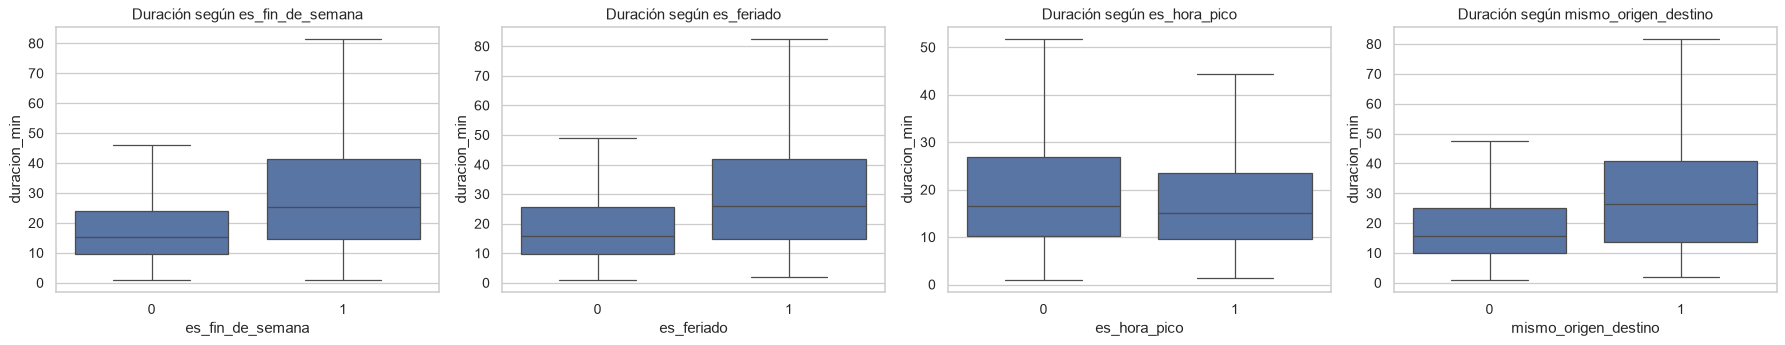

In [35]:
# ¿Los nuevos features se relacionan con la target? (muestra de train)
mt = X_train.sample(MUESTRA, random_state=SEED).join(y_train)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['es_fin_de_semana', 'es_feriado', 'es_hora_pico', 'mismo_origen_destino']):
    sns.boxplot(data=mt, x=col, y=TARGET, ax=ax, showfliers=False)
    ax.set_title(f'Duración según {col}')
plt.tight_layout(); plt.show()

**Interpretación:** fines de semana, feriados y viajes que vuelven al mismo lugar son claramente más largos; los de hora pico, más cortos. Los features creados capturan información que no estaba explícita.

# 13. Discretización (clase 5)
Aplicamos dos métodos vistos en clase:
1. **Rango fijo (por dominio)** con `pd.cut` → `franja_horaria` (madrugada 0–6, mañana 6–12, tarde 12–18, noche 18–24): más interpretable que 24 horas.
2. **Puntos de corte (cuantiles)** con `KBinsDiscretizer(strategy='quantile')` → `rango_distancia` en 5 grupos con igual cantidad de viajes (*fit* en train). Adecuado porque la distancia es asimétrica: intervalos de igual ancho dejarían grupos casi vacíos. Ya devuelve los códigos ordinales (no hay que codificar).

Cortes de distancia (km) calculados en train: [ 0.    0.93  1.47  2.1   3.13 15.22]


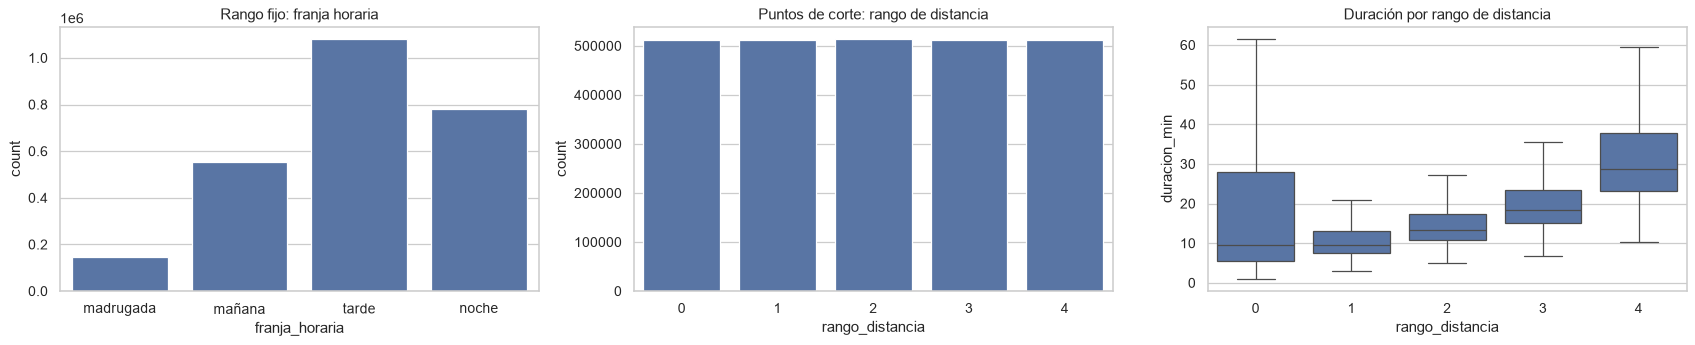

In [36]:
# Rango fijo: cortes manuales definidos por dominio
cortes = [-np.inf, 5, 11, 17, np.inf]
etiquetas = ['madrugada', 'mañana', 'tarde', 'noche']
for X_ in (X_train, X_test):
    X_['franja_horaria'] = pd.cut(X_['hora'], bins=cortes, labels=etiquetas, include_lowest=True)

# Puntos de corte (cuantiles): CALCULAR en train, APLICAR en test
kbin_quantile = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile', subsample=None)
X_train['rango_distancia'] = kbin_quantile.fit_transform(X_train[['distancia_km']]).astype(int).ravel()
X_test['rango_distancia'] = kbin_quantile.transform(X_test[['distancia_km']]).astype(int).ravel()
print('Cortes de distancia (km) calculados en train:', np.round(kbin_quantile.bin_edges_[0], 2))

fig, axes = plt.subplots(1, 3, figsize=(19, 4))
sns.countplot(x='franja_horaria', data=X_train, ax=axes[0]); axes[0].set_title('Rango fijo: franja horaria')
sns.countplot(x='rango_distancia', data=X_train, ax=axes[1]); axes[1].set_title('Puntos de corte: rango de distancia')
mt = X_train.sample(MUESTRA, random_state=SEED).join(y_train)
sns.boxplot(data=mt, x='rango_distancia', y=TARGET, ax=axes[2], showfliers=False)
axes[2].set_title('Duración por rango de distancia')
plt.tight_layout(); plt.show()

Cortes obtenidos en train: 0,93 · 1,47 · 2,1 · 3,13 km. Se ve una relación **monótona** clara: a mayor rango de distancia, mayor duración. El primer grupo incluye los viajes de distancia 0 (vuelven a la misma estación), con duraciones muy dispersas.

# 14. Codificación de variables categóricas (clase 4)
La técnica depende del **tipo de variable** y de su **cardinalidad**:

| Variable | Tipo / cardinalidad | Codificación | Motivo |
|---|---|---|---|
| `modelo_bicicleta` | Binaria | 0/1 (una sola columna, con `map`) | Recomendación para binarias |
| `genero` | Nominal, 4 categorías | **One-Hot** (`OneHotEncoder`) | Baja cardinalidad, sin orden |
| `franja_horaria` | Nominal, 4 categorías | **One-Hot** (`OneHotEncoder`) | Baja cardinalidad |
| `hora`, `dia_semana`, `mes` | Cíclicas | **Cyclic encoding** (seno y coseno) | Las 23 h están "cerca" de las 0 h; diciembre de enero |
| `rango_distancia` | Ordinal | **Ordinal** (0–4, ya lo devuelve `KBinsDiscretizer`) | Conserva el orden |
| `id_usuario` | Nominal, ~250 mil categorías | **Frequency encoding** | La frecuencia de uso aporta información sobre la target (usuarios frecuentes → viajes cortos) |
| `id_estacion_origen` / `destino` | Nominal, ~400 categorías | **Target encoding** (`TargetEncoder`) | Alta cardinalidad: one-hot crearía ~800 columnas |

Todos los encoders se ajustan (*fit*) en TRAIN y se aplican (*transform*) en TEST. **Cuidado con el target encoding:** tiene riesgo de sobreajuste; el `TargetEncoder` de `category_encoders` lo mitiga con **suavizado** (mezcla la media de cada categoría con la media global).

In [37]:
# --- Binaria: una sola columna 0/1
for X_ in (X_train, X_test):
    X_['modelo_iconic'] = X_['modelo_bicicleta'].map({'FIT': 0, 'ICONIC': 1}).astype(int)

# --- One-Hot encoding con OneHotEncoder de Scikit-learn
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
cols_ohe = ['genero', 'franja_horaria']

X_train_ohe = pd.DataFrame(ohe.fit_transform(X_train[cols_ohe]),              # fit + transform en train
                           columns=ohe.get_feature_names_out(cols_ohe), index=X_train.index)
X_test_ohe = pd.DataFrame(ohe.transform(X_test[cols_ohe]),                     # solo transform en test
                          columns=ohe.get_feature_names_out(cols_ohe), index=X_test.index)
X_train = X_train.join(X_train_ohe)
X_test = X_test.join(X_test_ohe)
cols_genero = [c for c in ohe.get_feature_names_out(cols_ohe) if c.startswith('genero_')]
print('Columnas one-hot:', list(ohe.get_feature_names_out(cols_ohe)))

# --- Cyclic encoding
for X_ in (X_train, X_test):
    for col, periodo in [('hora', 24), ('dia_semana', 7), ('mes', 12)]:
        X_[f'{col}_sin'] = np.sin(2 * np.pi * X_[col] / periodo)
        X_[f'{col}_cos'] = np.cos(2 * np.pi * X_[col] / periodo)

# --- Frequency encoding de id_usuario: CALCULAR en train, APLICAR en test
freq_encoding = X_train['id_usuario'].value_counts(normalize=True)
X_train['freq_usuario'] = X_train['id_usuario'].map(freq_encoding)
X_test['freq_usuario'] = X_test['id_usuario'].map(freq_encoding).fillna(freq_encoding.min())  # usuario nuevo -> frecuencia mínima

# --- Target encoding de las estaciones: CALCULAR en train, APLICAR en test
cols_te = ['id_estacion_origen', 'id_estacion_destino']
target_encoder = TargetEncoder(cols=cols_te)
te_train = target_encoder.fit_transform(X_train[cols_te], y_train)    # usa la target de TRAIN
te_test = target_encoder.transform(X_test[cols_te])
X_train[['te_estacion_origen', 'te_estacion_destino']] = te_train.values
X_test[['te_estacion_origen', 'te_estacion_destino']] = te_test.values

X_train[['modelo_iconic', 'hora_sin', 'hora_cos', 'freq_usuario', 'te_estacion_origen', 'te_estacion_destino'] + cols_genero].head()

Columnas one-hot: ['genero_FEMALE', 'genero_MALE', 'genero_NO_INFORMADO', 'genero_OTHER', 'franja_horaria_madrugada', 'franja_horaria_mañana', 'franja_horaria_noche', 'franja_horaria_tarde']


,modelo_iconic,hora_sin,hora_cos,freq_usuario,te_estacion_origen,te_estacion_destino,genero_FEMALE,genero_MALE,genero_NO_INFORMADO,genero_OTHER
2816753,0,-0.966,-0.259,0.000,20.074,23.007,0.000,1.000,0.000,0.000
1906499,0,0.500,-0.866,0.000,19.397,21.288,1.000,0.000,0.000,0.000
1554067,0,0.259,0.966,0.000,24.009,17.656,1.000,0.000,0.000,0.000
1968109,0,-0.707,-0.707,0.000,19.194,20.841,0.000,1.000,0.000,0.000
540283,0,0.000,1.000,0.000,19.070,18.487,0.000,1.000,0.000,0.000


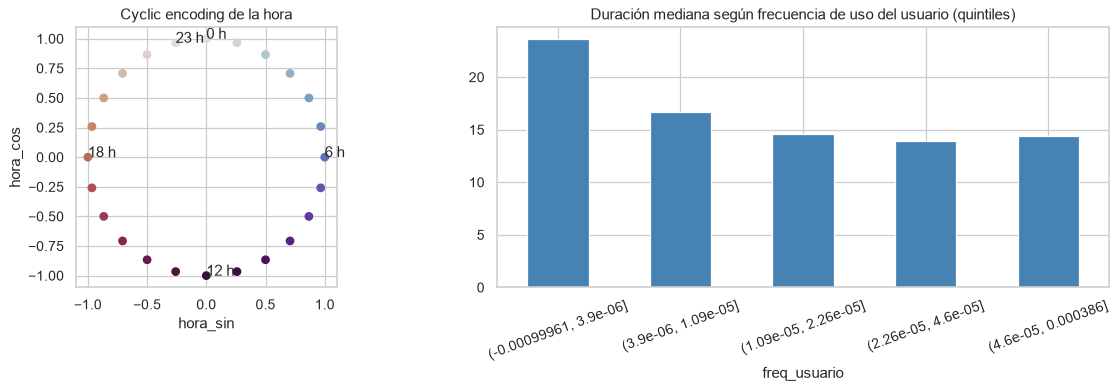

In [38]:
# Visualizamos el cyclic encoding de la hora y la relación de la frecuencia de uso con la target
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
h = pd.DataFrame({'hora': range(24)})
axes[0].scatter(np.sin(2*np.pi*h.hora/24), np.cos(2*np.pi*h.hora/24), c=h.hora, cmap='twilight')
for i in [0, 6, 12, 18, 23]:
    axes[0].annotate(f'{i} h', (np.sin(2*np.pi*i/24), np.cos(2*np.pi*i/24)))
axes[0].set_title('Cyclic encoding de la hora'); axes[0].set_xlabel('hora_sin'); axes[0].set_ylabel('hora_cos'); axes[0].set_aspect('equal')

mt = X_train.sample(MUESTRA, random_state=SEED).join(y_train)
mt['freq_usuario_q'] = pd.qcut(mt['freq_usuario'], 5, duplicates='drop')
mt.groupby('freq_usuario_q', observed=True)[TARGET].median().plot.bar(ax=axes[1], color='steelblue')
axes[1].set_title('Duración mediana según frecuencia de uso del usuario (quintiles)'); axes[1].set_xlabel('freq_usuario')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Interpretación:** los **usuarios frecuentes hacen viajes más cortos** (uso como transporte) y los esporádicos, viajes más largos (uso recreativo): el frequency encoding captura información útil sobre la target.

# 15. Escalado (clase 5)
- Usamos **estandarización (Z-score)** con `StandardScaler`: media 0 y desvío 1. La elegimos frente a la normalización Min-Max porque varias features tienen colas largas (`freq_usuario`, `distancia_km`) y Min-Max quedaría dominado por los máximos. Además **PCA requiere estandarizar**.
- `freq_usuario` tiene una cola muy larga → antes le aplicamos una **transformación logarítmica** (como en el tratamiento de outliers de la clase 4) y después estandarizamos.
- Escalamos **solo las numéricas continuas**. No escalamos: one-hot y binarias (ya son 0/1), cíclicas (ya están entre −1 y 1; escalarlas rompería el círculo) ni la ordinal `rango_distancia`.
- El scaler se ajusta en TRAIN y se aplica en TEST.

,distancia_km,lat_estacion_origen,long_estacion_origen,lat_estacion_destino,long_estacion_destino,log_freq_usuario,te_estacion_origen,te_estacion_destino
mean,2.108,-34.599,-58.423,-34.599,-58.423,-11.256,20.750,20.750
std,1.549,0.024,0.038,0.025,0.039,1.432,3.001,3.269
min,0.000,-34.688,-58.527,-34.688,-58.527,-14.757,14.729,14.773
max,15.215,-34.537,-58.355,-34.537,-58.355,-7.859,38.143,41.713


,distancia_km,lat_estacion_origen,long_estacion_origen,lat_estacion_destino,long_estacion_destino,log_freq_usuario,te_estacion_origen,te_estacion_destino
mean,-0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.361,-3.690,-2.721,-3.620,-2.702,-2.445,-2.006,-1.828
max,8.463,2.568,1.759,2.532,1.755,2.372,5.796,6.412


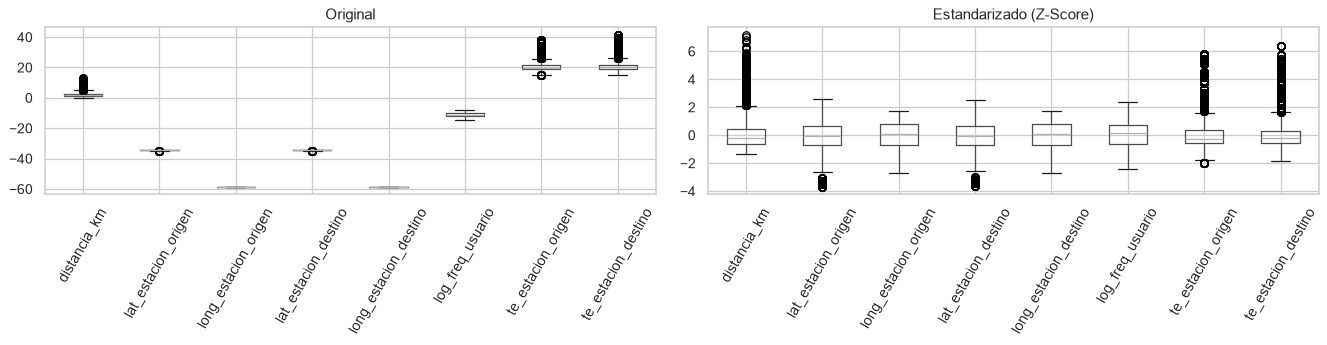

In [39]:
for X_ in (X_train, X_test):
    X_['log_freq_usuario'] = np.log(X_['freq_usuario'])

NUM_ESCALAR = ['distancia_km', 'lat_estacion_origen', 'long_estacion_origen',
               'lat_estacion_destino', 'long_estacion_destino',
               'log_freq_usuario', 'te_estacion_origen', 'te_estacion_destino']

# Estandarización (Z-Score)
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train[NUM_ESCALAR]), columns=NUM_ESCALAR, index=X_train.index)  # fit + transform
X_test_std = pd.DataFrame(scaler.transform(X_test[NUM_ESCALAR]), columns=NUM_ESCALAR, index=X_test.index)        # solo transform

display(X_train[NUM_ESCALAR].describe().loc[['mean', 'std', 'min', 'max']])
display(X_train_std.describe().loc[['mean', 'std', 'min', 'max']].round(6))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
X_train[NUM_ESCALAR].sample(20_000, random_state=SEED).boxplot(ax=axes[0], rot=60); axes[0].set_title('Original')
X_train_std.sample(20_000, random_state=SEED).boxplot(ax=axes[1], rot=60); axes[1].set_title('Estandarizado (Z-Score)')
plt.tight_layout(); plt.show()

X_train[NUM_ESCALAR] = X_train_std
X_test[NUM_ESCALAR] = X_test_std

Después de estandarizar todas las variables quedan en la **misma escala** (media 0, desvío 1 en train). Como vimos en clase, la media, la varianza y la covarianza cambian, pero la **correlación de Pearson permanece igual**.

# 16. Desbalance de clases: no aplica (problema de regresión)
La consigna pide analizar el desbalance **"en el caso que se trate de un problema de clasificación"**. El nuestro es de **regresión**: la target es continua y no hay clases que puedan estar sub- o sobrerrepresentadas, así que este paso **no corresponde**.

Lo que sí cumple un rol parecido en regresión es la **distribución de la target**: la duración es muy asimétrica (muchos viajes cortos, pocos muy largos). Eso ya lo tratamos con:
- el **capping** en el p99 de train (sección 11), para que los viajes extremos no dominen el modelo;
- la opción de predecir **log(duración)** (sección 8), que vuelve la distribución casi simétrica;
- el **split estratificado por tramos de duración** (sección 9), para que train y test tengan la misma proporción de viajes largos.

*Si el problema fuera de clasificación* (por ejemplo, "¿el viaje supera los 30 minutos?"), mediríamos el desbalance con proporciones y entropía de Shannon, y lo trataríamos **solo en train** con `RandomUnderSampler` (sobran datos) o `SMOTE`, sin balancear nunca el test.

# 17. Selección de features (clase 6)
Seguimos los 4 criterios de clase:
- **(A)** features irrelevantes, no disponibles o no confiables (criterio y dominio).
- **(B)** features **redundantes** (asociación feature–feature).
- **(C)** features con relación **demasiado fuerte** con la target (posible leakage).
- **(D)** **relevancia predictiva** (test F e información mutua, con `SelectKBest`).

Trabajamos sobre una muestra de train para los cálculos pesados.

### (A) Criterio y conocimiento del dominio
Ya descartamos en las secciones 7–8: `fecha_destino` (no disponible al predecir: leakage), `id_recorrido` (irrelevante), nombres y direcciones (redundantes), `id_usuario` crudo. Las coordenadas de las estaciones quedan como candidatas.

### (B) Redundancia entre features

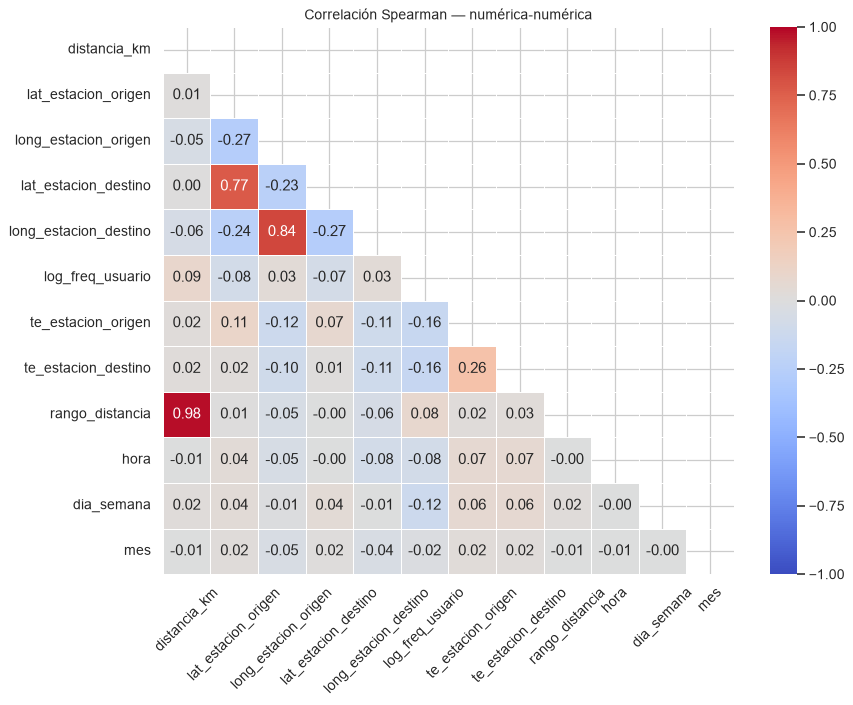

In [40]:
num_features = ['distancia_km', 'lat_estacion_origen', 'long_estacion_origen', 'lat_estacion_destino',
                'long_estacion_destino', 'log_freq_usuario', 'te_estacion_origen', 'te_estacion_destino',
                'rango_distancia', 'hora', 'dia_semana', 'mes']
bin_features = ['mismo_origen_destino', 'es_fin_de_semana', 'es_feriado', 'es_hora_pico', 'modelo_iconic']
cat_nom_features = ['genero', 'franja_horaria']

ms = X_train.sample(MUESTRA, random_state=SEED)
y_ms = y_train.loc[ms.index]

# Correlación de Spearman (numérica - numérica)
corr_spearman = ms[num_features].corr(method='spearman')
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))  # máscara para mostrar solo la mitad inferior
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5, center=0, mask=mask, ax=ax)
ax.set_title("Correlación Spearman — numérica-numérica", fontsize=11)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

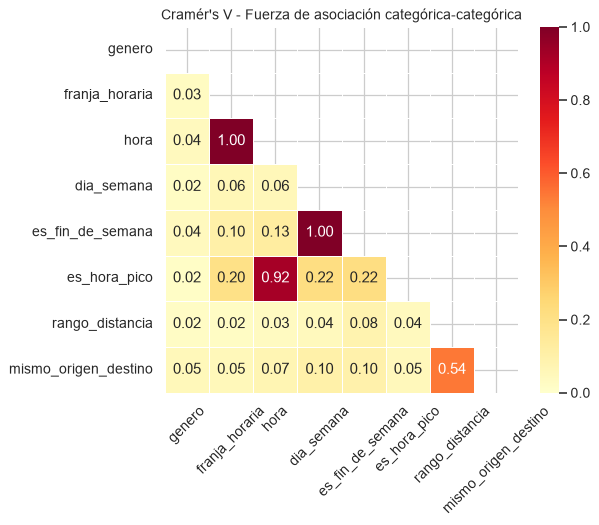

In [41]:
# Cramér's V (categórica - categórica)
cat_cols = cat_nom_features + ['hora', 'dia_semana', 'es_fin_de_semana', 'es_hora_pico', 'rango_distancia', 'mismo_origen_destino']

v_mat = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for c1 in cat_cols:
    for c2 in cat_cols:
        if c1 == c2:
            v_mat.loc[c1, c2] = 1.0
        else:
            v_mat.loc[c1, c2] = cramers_v(ms[c1], ms[c2])

mask = np.triu(np.ones_like(v_mat, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(v_mat.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, mask=mask, ax=ax)
ax.set_title("Cramér's V - Fuerza de asociación categórica-categórica", fontsize=11)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

**Redundancias encontradas:**
- `franja_horaria` ↔ `hora`: la franja es una discretización de la hora (información repetida) → nos quedamos con la hora en **encoding cíclico** (más detalle) y descartamos la franja para el modelo.
- `dia_semana` ↔ `es_fin_de_semana`: muy asociados → conservamos `es_fin_de_semana` (resume lo esencial que vimos en el EDA) + el encoding cíclico del día.
- `rango_distancia` ↔ `distancia_km`: casi 1 (Spearman) → es la versión discretizada; conservamos la continua.
- `mismo_origen_destino` ↔ `rango_distancia`: la distancia 0 ya lo indica, pero lo conservamos porque capta un comportamiento **distinto** (paseo) que un modelo lineal no inferiría de "distancia = 0".
- Coordenadas lat/long de origen y destino: correlación alta entre origen y destino del mismo eje (la gente viaja cerca) → candidatas a resumir con PCA.

### (C) Asociación de cada feature con la target
Como la target es **numérica**, usamos la medida que corresponde a cada tipo de feature (tabla de la clase 6): **Spearman** (numéricas), **punto biserial** (binarias) y **eta cuadrado** (nominales).

In [42]:
asoc_target = {}
for col in num_features:                       # numérica - numérica
    asoc_target[(col, 'Spearman')] = ms[col].corr(y_ms, method='spearman')
for col in bin_features:                       # binaria - numérica
    r, _ = pointbiserialr(ms[col], y_ms)
    asoc_target[(col, 'Punto biserial')] = r
for col in cat_nom_features:                   # nominal - numérica
    eta2, p, F = eta_squared(y_ms, ms[col])
    asoc_target[(col, 'Eta cuadrado')] = eta2

asoc_target = pd.Series(asoc_target).rename('asociación con la duración').to_frame()
asoc_target['|valor|'] = asoc_target.iloc[:, 0].abs()
asoc_target.sort_values('|valor|', ascending=False).round(3)

,,asociación con la duración,|valor|
rango_distancia,Spearman,0.522,0.522
distancia_km,Spearman,0.516,0.516
es_fin_de_semana,Punto biserial,0.248,0.248
log_freq_usuario,Spearman,-0.237,0.237
te_estacion_destino,Spearman,0.181,0.181
mismo_origen_destino,Punto biserial,0.175,0.175
te_estacion_origen,Spearman,0.169,0.169
dia_semana,Spearman,0.131,0.131
es_feriado,Punto biserial,0.116,0.116
hora,Spearman,0.086,0.086


### (D) Relevancia predictiva: test F e información mutua
Usamos `SelectKBest` con `f_regression` (equivalente al ANOVA/F de la clase, para target numérica) y `mutual_info_regression` (información mutua). Las nominales entran con su codificación one-hot (como se vio en clase, así se analiza **por categoría**).

,F,p_value,MI
distancia_km,33944.7,0.000,0.563
rango_distancia,19626.4,0.000,0.437
log_freq_usuario,18516.5,0.000,0.053
te_estacion_destino,8063.8,0.000,0.036
lat_estacion_destino,1.3,0.253,0.035
te_estacion_origen,6845.0,0.000,0.033
es_fin_de_semana,13084.2,0.000,0.028
long_estacion_destino,33.1,0.000,0.027
lat_estacion_origen,6.8,0.009,0.026
mismo_origen_destino,6346.3,0.000,0.025


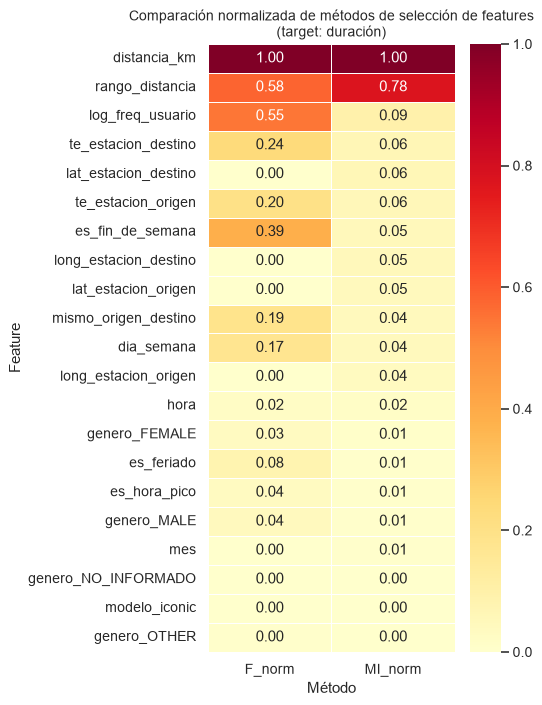

In [43]:
features_relevancia = num_features + bin_features + cols_genero
X_sel = ms[features_relevancia]

# Test F (relación lineal con la target)
selector_f = SelectKBest(score_func=f_regression, k='all')
selector_f.fit(X_sel, y_ms)
f_scores = pd.Series(selector_f.scores_, index=features_relevancia, name='F')
f_pvals  = pd.Series(selector_f.pvalues_, index=features_relevancia, name='F_pval')

# Información mutua (capta relaciones no lineales). Es costosa: usamos 50 mil filas
ms_mi = ms.sample(50_000, random_state=SEED)
continuas = ['distancia_km', 'lat_estacion_origen', 'long_estacion_origen', 'lat_estacion_destino',
             'long_estacion_destino', 'log_freq_usuario', 'te_estacion_origen', 'te_estacion_destino']
mi = mutual_info_regression(ms_mi[features_relevancia], y_train.loc[ms_mi.index],
                            discrete_features=[c not in continuas for c in features_relevancia], random_state=42)
mi_scores = pd.Series(mi, index=features_relevancia, name='MI')

display(pd.DataFrame({'F': f_scores, 'p_value': f_pvals, 'MI': mi_scores})
          .sort_values('MI', ascending=False).style.format({'F': '{:.1f}', 'p_value': '{:.3f}', 'MI': '{:.3f}'}))

# Comparación normalizada de los métodos (como en la clase 6)
comparison_df = pd.DataFrame(index=features_relevancia)
comparison_df['F_norm'] = MinMaxScaler().fit_transform(f_scores.values.reshape(-1, 1)).flatten()
comparison_df['MI_norm'] = MinMaxScaler().fit_transform(mi_scores.values.reshape(-1, 1)).flatten()
comparison_df = comparison_df.sort_values('MI_norm', ascending=False)

fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(comparison_df.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Comparación normalizada de métodos de selección de features\n(target: duración)", fontsize=11)
ax.set_xlabel("Método"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

**Interpretación:**
- **(C)** Ninguna feature tiene una relación "demasiado fuerte" con la target (ninguna cercana a 1) → **no hay indicios de leakage** entre las candidatas (el leakage real, la fecha de destino, ya fue excluido).
- **(D)** Las features más relevantes, por información mutua y por F, son: **`distancia_km`** (por lejos), `rango_distancia`, la **frecuencia de uso del usuario**, los **target encodings** de destino y origen, y luego `es_fin_de_semana`, `dia_semana` y `mismo_origen_destino`. Género, feriado, mes y modelo aportan poco.
- No nos quedamos con un solo método: comparamos MI (capta relaciones **no lineales**) con F (solo lineal). Ejemplo claro: las **coordenadas** tienen F casi 0 (no hay relación *lineal*: ir más al norte no alarga el viaje) pero MI apreciable (la *ubicación* sí importa, de forma no lineal) → las conservamos.

**Criterio de reducción y conjunto final:** descartamos las redundantes (`franja_horaria`, `rango_distancia`, `dia_semana` ordinal) y conservamos las de mayor relevancia más las temporales cíclicas. Mantenemos género y modelo (aportan poco, pero son baratos y podrían interactuar con otras en modelos de árbol); se podrían quitar en una segunda iteración con validación del modelo.

In [44]:
FEATURES_FINALES = (
    ['distancia_km', 'mismo_origen_destino', 'te_estacion_origen', 'te_estacion_destino',
     'lat_estacion_origen', 'long_estacion_origen', 'lat_estacion_destino', 'long_estacion_destino',
     'log_freq_usuario', 'es_fin_de_semana', 'es_feriado', 'es_hora_pico', 'modelo_iconic',
     'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos', 'mes_sin', 'mes_cos']
    + cols_genero)

X_train = X_train[FEATURES_FINALES]
X_test = X_test[FEATURES_FINALES]

print('Features finales:', len(FEATURES_FINALES))
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

Features finales: 23
X_train: (2563561, 23) | X_test: (640891, 23)


# 18. Extracción de features: PCA (clase 7)
PCA busca **nuevos ejes** (componentes principales) ordenados por la cantidad de **varianza** que capturan. Seguimos los pasos de la notebook de la clase 7:
- **Paso 1)** Calculamos los ejes principales (PC1, PC2, …): **autovectores** (*loadings*) y **autovalores** (varianza explicada).
- **Paso 2)** Calculamos los datos proyectados sobre esos ejes (**scores**).
- **Paso 3)** Preparamos los datasets de train y test con los datos transformados.

**Lo aplicamos a las features numéricas continuas** (coordenadas, distancia, target encodings, frecuencia de usuario), que ya están **estandarizadas** (sección 15): como vimos en clase, `PCA` de sklearn centra los datos pero **no los escala**. No incluimos binarias / one-hot / cíclicas: PCA asume relaciones lineales y trabaja con varianza, que en variables 0/1 no tiene el mismo significado. *Fit* en TRAIN, *transform* en TEST.

### Paso 1) Calculamos los ejes principales PC1, PC2, etc.

In [45]:
PCA_COLS = NUM_ESCALAR   # 8 numéricas continuas, ya estandarizadas
X_train_scaled = X_train[PCA_COLS]
X_test_scaled = X_test[PCA_COLS]

# Análisis de los componentes principales (PCA) en TRAIN
pca = PCA(n_components=len(PCA_COLS))   # primero calculamos todos los componentes para ver la varianza de cada uno

# Ajusta el PCA (calcula componentes, autovalores, etc.)
pca.fit(X_train_scaled)

print("Varianza de cada componente (autovalores):", np.round(pca.explained_variance_, 3))

Varianza de cada componente (autovalores): [2.275 1.53  1.392 1.01  0.816 0.615 0.223 0.14 ]


In [46]:
# Verificación "artesanal" con numpy (como en la clase): autovalores de la matriz de covarianza
cov_matrix = np.cov(X_train_scaled.sample(200_000, random_state=SEED), rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_matrix)
eigvals = eigvals[np.argsort(eigvals)[::-1]]   # ordenamos de mayor a menor
print("Autovalores con numpy (muestra):", np.round(eigvals, 3))

Autovalores con numpy (muestra): [2.272 1.512 1.388 1.012 0.817 0.611 0.223 0.14 ]


#### Varianza capturada por cada componente y varianza acumulada

[0.284 0.191 0.174 0.126 0.102 0.077 0.028 0.017]
[0.284 0.476 0.65  0.776 0.878 0.955 0.983 1.   ]


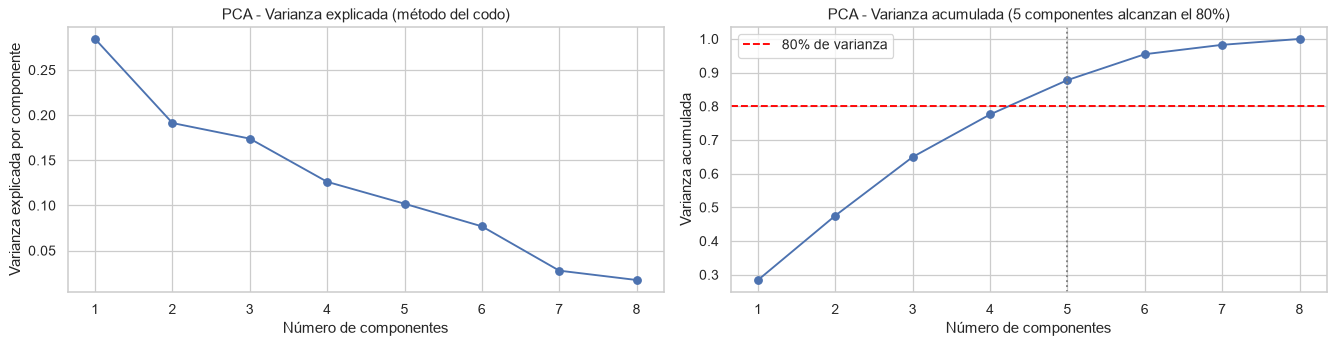

In [47]:
# % de varianza capturada por cada componente
explained_var = pca.explained_variance_ratio_
print(np.round(explained_var, 3))

# varianza acumulada
cumulative_var = np.cumsum(explained_var)
print(np.round(cumulative_var, 3))

n_components = len(explained_var)
componentes = np.arange(1, n_components + 1)
k80 = int(np.argmax(cumulative_var >= 0.80) + 1)   # criterio: acumular al menos 70-80% de la varianza

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(componentes, explained_var, marker='o')
axes[0].set_xticks(componentes)
axes[0].set_xlabel('Número de componentes'); axes[0].set_ylabel('Varianza explicada por componente')
axes[0].set_title('PCA - Varianza explicada (método del codo)'); axes[0].grid(True)

axes[1].plot(componentes, cumulative_var, marker='o')
axes[1].set_xticks(componentes)
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% de varianza')
axes[1].axvline(x=k80, color='gray', linestyle=':')
axes[1].set_xlabel('Número de componentes'); axes[1].set_ylabel('Varianza acumulada')
axes[1].set_title(f'PCA - Varianza acumulada ({k80} componentes alcanzan el 80%)'); axes[1].grid(True); axes[1].legend()
plt.tight_layout(); plt.show()

Elegimos **k = 5 componentes**: con 4 se llega al 77,6% y con 5 al 87,8%, superando el criterio estándar de 70–80% de la varianza; el codo del gráfico también aparece alrededor de PC4–PC5. Reajustamos el PCA con ese número de componentes.

#### Loadings
Cuánto aporta cada variable a cada componente principal.

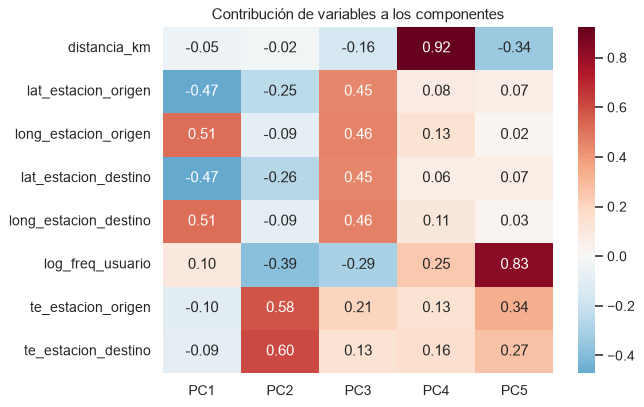

In [48]:
pca = PCA(n_components=k80)
pca.fit(X_train_scaled)

columnas_pc = [f'PC{i+1}' for i in range(k80)]
loadings = pd.DataFrame(
    pca.components_.T,
    columns=columnas_pc,
    index=PCA_COLS
)

plt.figure(figsize=(7, 5))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title("Contribución de variables a los componentes")
plt.show()

#### Contribuciones porcentuales por componente

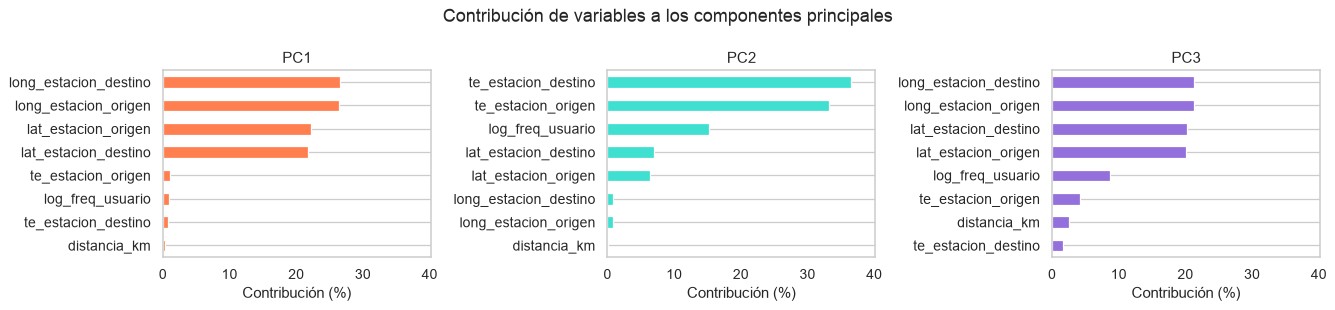

In [49]:
# Contribuciones porcentuales
contrib = (loadings**2)
contrib = contrib.div(contrib.sum(axis=0), axis=1) * 100

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=False)
for i, (pc, color) in enumerate(zip(['PC1', 'PC2', 'PC3'], ['coral', 'turquoise', 'mediumpurple'])):
    contrib[pc].sort_values().plot.barh(ax=ax[i], color=color)
    ax[i].set_title(pc)
    ax[i].set_xlabel("Contribución (%)")
    ax[i].grid(axis='x')

# escala
max_val = contrib[['PC1', 'PC2', 'PC3']].max().max()
for i in range(3):
    ax[i].set_xlim(0, max_val * 1.1)

plt.suptitle("Contribución de variables a los componentes principales")
plt.tight_layout()
plt.show()

### Paso 2) Calculamos los datos proyectados sobre los ejes principales.
#### Scores
Datos proyectados sobre los componentes principales.

In [50]:
# datos proyectados sobre los componentes principales (scores)
X_train_scores = pca.transform(X_train_scaled)
X_train_scores[0:10]

array([[-1.14586710e+00,  1.53264254e+00, -2.89195055e+00,
         2.68516058e-01, -1.12469025e+00],
       [-6.06837586e-01, -4.88137904e-01, -7.09900631e-01,
         7.72823245e-01,  2.74299920e-01],
       [ 1.54611711e-02, -4.78053519e-01,  8.00295162e-01,
         2.84871077e-01,  6.46373457e-01],
       [-2.07831553e+00, -5.81011980e-01, -1.75516708e+00,
         1.47683486e-01,  5.53860293e-01],
       [ 2.02358486e+00, -6.47496679e-01, -5.92670322e-01,
         4.48921592e-04,  1.71938635e-01],
       [ 3.63965404e-01, -9.62166169e-01,  5.18158991e-02,
        -3.82709628e-01, -1.65940786e-01],
       [-9.71687811e-01,  4.72768578e-01,  6.64150756e-01,
        -5.05182980e-01, -7.05500080e-01],
       [ 8.01044702e-01, -1.06338199e+00,  6.85457195e-01,
        -1.34801773e-01, -1.51062242e-01],
       [-5.81074772e-01, -2.21670464e-02, -9.67878513e-01,
        -1.40441922e+00,  7.64505850e-01],
       [ 1.28917537e+00, -1.71185228e+00,  9.18108219e-01,
         4.85933571e-01

#### Biplot
Con un biplot vemos en un solo gráfico:
- **puntos:** observaciones proyectadas sobre PC1 y PC2 (scores). Las coloreamos según la duración del viaje (nuestra target es continua, por eso usamos una escala de color en lugar de clases).
- **vectores:** las variables originales y su contribución a los componentes principales (loadings).

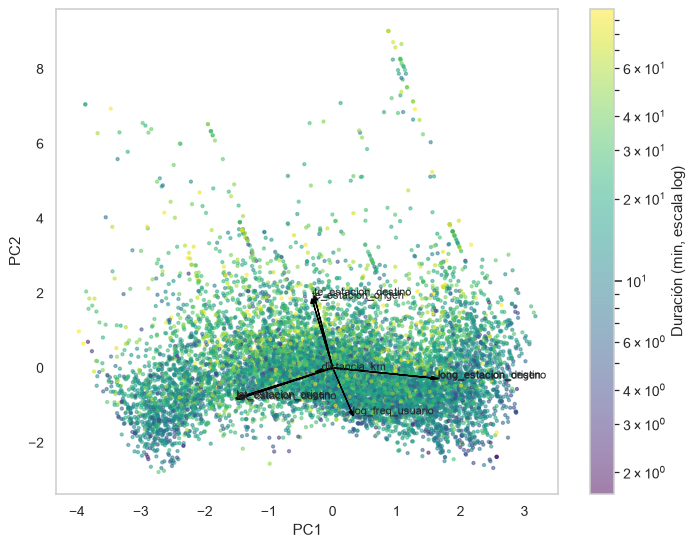

In [51]:
def plot_biplot(scores, loadings, feature_names, y=None, n=10_000):
    # Para que el gráfico sea legible usamos una muestra de n observaciones
    idx = np.random.RandomState(42).choice(len(scores), size=min(n, len(scores)), replace=False)

    plt.figure(figsize=(9, 7))
    if y is None:
        plt.scatter(scores[idx, 0], scores[idx, 1], alpha=0.4, s=6, color="#008392")
    else:
        sc = plt.scatter(scores[idx, 0], scores[idx, 1], c=np.asarray(y)[idx], alpha=0.5, s=6,
                         cmap='viridis', norm=matplotlib.colors.LogNorm())
        plt.colorbar(sc, label='Duración (min, escala log)')

    for i, feature in enumerate(feature_names):
        plt.arrow(0, 0, loadings.iloc[i, 0] * 3, loadings.iloc[i, 1] * 3, head_width=0.08, color='black')
        plt.text(loadings.iloc[i, 0] * 3.2, loadings.iloc[i, 1] * 3.2, feature, fontsize=9)

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid()
    plt.show()

plot_biplot(X_train_scores, loadings, PCA_COLS, y=y_train)

### Paso 3) Preparamos los datasets de train y test con los datos transformados
Reemplazamos las 8 variables numéricas por los 5 componentes. El dataset de test tiene que tener el mismo formato (columnas) que el de train, por eso usamos el PCA **ajustado en train** (solo `transform`).

In [52]:
X_test_scores = pca.transform(X_test_scaled)   # scores de test con el PCA ajustado en train

df_train_pca = pd.DataFrame(X_train_scores, columns=columnas_pc, index=X_train.index)
df_test_pca = pd.DataFrame(X_test_scores, columns=columnas_pc, index=X_test.index)

X_train_pca = pd.concat([X_train.drop(columns=PCA_COLS), df_train_pca], axis=1)
X_test_pca = pd.concat([X_test.drop(columns=PCA_COLS), df_test_pca], axis=1)

print(f'Dimensiones: {X_train.shape[1]} features -> {X_train_pca.shape[1]} features con PCA '
      f'({len(PCA_COLS)} numéricas reemplazadas por {k80} componentes, {cumulative_var[k80-1]:.0%} de su varianza)')
X_train_pca.head()

Dimensiones: 23 features -> 20 features con PCA (8 numéricas reemplazadas por 5 componentes, 88% de su varianza)


,mismo_origen_destino,es_fin_de_semana,es_feriado,es_hora_pico,modelo_iconic,hora_sin,hora_cos,dia_semana_sin,dia_semana_cos,mes_sin,mes_cos,genero_FEMALE,genero_MALE,genero_NO_INFORMADO,genero_OTHER,PC1,PC2,PC3,PC4,PC5
2816753,0,0,0,1,0,-0.966,-0.259,0.975,-0.223,0.500,0.866,0.000,1.000,0.000,0.000,-1.146,1.533,-2.892,0.269,-1.125
1906499,0,0,0,0,0,0.500,-0.866,-0.434,-0.901,-0.500,0.866,1.000,0.000,0.000,0.000,-0.607,-0.488,-0.710,0.773,0.274
1554067,0,0,0,0,0,0.259,0.966,0.975,-0.223,-1.000,-0.000,1.000,0.000,0.000,0.000,0.015,-0.478,0.800,0.285,0.646
1968109,0,0,0,0,0,-0.707,-0.707,0.434,-0.901,-0.500,0.866,0.000,1.000,0.000,0.000,-2.078,-0.581,-1.755,0.148,0.554
540283,0,0,0,0,0,0.000,1.000,0.975,-0.223,-0.866,0.500,0.000,1.000,0.000,0.000,2.024,-0.647,-0.593,0.000,0.172


**Interpretación de PCA:**
- Los **loadings** y las **contribuciones porcentuales** muestran qué resume cada componente: **PC1** y **PC3** combinan las **4 coordenadas** (origen y destino juntas, porque están muy correlacionadas) y representan la **ubicación del viaje en la ciudad** en dos ejes diagonales. **PC2** agrupa los **target encodings** de origen y destino (estaciones donde los viajes suelen ser largos), en oposición a la frecuencia de uso. **PC4** es casi pura **distancia** y **PC5** casi pura **frecuencia del usuario**.
- Con **5 componentes se retiene ≈ 88%** de la varianza de las 8 variables numéricas. El último autovalor (PC8 ≈ 1,7%) confirma la redundancia entre coordenadas. Los autovalores calculados "a mano" con numpy coinciden con los de sklearn.
- En el **biplot**, los viajes cortos y largos **se mezclan**: PCA no ordena los datos según la duración porque busca varianza, **no** relación con la target (es no supervisado). Las flechas de las coordenadas apuntan juntas de a pares (origen y destino), lo que confirma visualmente su redundancia.

**Ventajas:** menos dimensiones (menor costo, menos riesgo de *curse of dimensionality*); elimina redundancia (las coordenadas de origen y destino están correlacionadas); componentes no correlacionadas entre sí (útil para modelos lineales); permite visualizar en 2D.

**Desventajas:** se pierde ~12% de la varianza de esas variables; como dice la notebook de clase, **PCA no conserva las variables individuales y se pierde interpretabilidad** (¿qué significa "PC2 = 1,3"?), cuando la distancia o la estación son fáciles de explicar; PCA solo capta relaciones **lineales**; no considera la target, por lo que puede descartar varianza que sí era predictiva.

**Conclusión sobre la reducción:** en este problema la dimensionalidad ya es moderada (23 features) frente a millones de filas, así que la reducción **no es imprescindible**. Dejamos ambas versiones (`X_train` y `X_train_pca`) para comparar en la etapa de modelado; por interpretabilidad preferiríamos la versión con selección de features.

# 19. Conclusiones

**Sobre el dataset**
- 3,56 M de viajes de Ecobici en 2024, 17 variables, mayoría categóricas y fechas. Uso **fuertemente laboral**: 87% en días hábiles, picos a las 8 y 17–18 h, más uso en primavera.
- La duración es **muy asimétrica** (mediana 15 min, cola de días) → usar estadística robusta (mediana, IQR) e IQR para outliers en lugar de 3σ.

**Calidad de datos (desafíos encontrados)**
- 1 duplicado. Faltantes en `fecha_destino` (0,09%) que **no son MCAR** sino **MAR**: aparecen todos desde el 7/11/2024 (falla/cambio del sistema) y sin duración → eliminados por no tener target.
- Faltantes en `genero` (0,34%) de 535 usuarios sin perfil completo, comportamiento ≈ MCAR respecto del viaje → categoría `NO_INFORMADO`.
- Faltantes "disfrazados" y errores: duraciones 0, **devoluciones inmediatas** (~250 mil), velocidades imposibles, viajes > 6 h (bici retenida de noche o no devuelta: fuera del alcance del problema). En total se eliminó ~10% de registros que no son viajes válidos.
- **Leakage detectado**: `fecha_destino` define la target → excluida.

**Preparación aplicada (siempre calculando en train y aplicando en test)**
- Split 80/20 estratificado · nulos con nueva categoría · capping p99 de la target · features nuevos (distancia, temporales, feriados, hora pico) · discretización (rango fijo y puntos de corte) · codificación (binaria, one-hot, cíclica, ordinal, frequency encoding, target encoding) · estandarización · desbalance: no aplica por ser regresión · selección de features (Spearman, V de Cramér, punto biserial, eta², test F, información mutua) · PCA.

**Hallazgos para el modelo**
- La **distancia** entre estaciones es la feature más predictiva; luego la estación de destino/origen, si el viaje vuelve al mismo lugar, la frecuencia de uso del usuario y el fin de semana.
- Aun así, la relación es ruidosa: el mismo trayecto puede ser un traslado directo o un paseo. Esperamos que un modelo **no lineal** (ej.: árboles / boosting) funcione mejor que uno lineal, y que predecir `log(duración)` ayude a los modelos lineales.
- PCA reduce dimensiones pero a costa de interpretabilidad; con pocas features y muchos datos no es indispensable.

In [53]:
# Resumen final de los conjuntos listos para entrenar
pd.DataFrame({
    'filas': [len(X_train), len(X_test), len(X_train_pca), len(X_test_pca)],
    'columnas': [X_train.shape[1], X_test.shape[1], X_train_pca.shape[1], X_test_pca.shape[1]],
}, index=['X_train', 'X_test', 'X_train_pca', 'X_test_pca'])

,filas,columnas
X_train,2563561,23
X_test,640891,23
X_train_pca,2563561,20
X_test_pca,640891,20
